<a href="https://colab.research.google.com/github/rifkyghifari/ML_PolaPenggunaanTransportasiUmum-B02-/blob/main/UTS_Kelompok4_B02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pola Penggunaan Transportasi Umum Berdasarkan Waktu dan Jenis Layanan

**Project ID:** B02

**Kelompok:** 4

**Metode:** Clustering (unsupervised learning)

**Anggota:**
1. Rifky Ghiffari Siregar - 231112918
2. Indra Jeremia Tinambunan - 231112760
3. Selamet Riyadi - 231112132

**Dataset:** Jumlah Penumpang Angkutan Umum yang Terlayani per Hari - Satu Data Jakarta
https://satudata.jakarta.go.id/open-data/detail?kategori=dataset&page_url=jumlah-penumpang-angkutan-umum-yang-terlayani-perhari&data_no=1

**Isi notebook:**
- **Minggu 2** - Data Understanding, EDA, dan Persiapan Data Awal
- **Minggu 3** - Preprocessing, Baseline, dan Evaluasi Awal
- **Minggu 4** - Kandidat Model dan Perbandingan Awal
- **Minggu 5** - Validasi dan Kestabilan
- **Minggu 6** - Clustering, PCA, Profil Cluster, dan Rencana Pasca-UTS

---
# MINGGU 2
## Data Understanding, EDA, dan Persiapan Data Awal

## 1. Project Identification

| Informasi | Keterangan |
|---|---|
| Project ID | B02 |
| Topik project | Pola penggunaan transportasi umum berdasarkan waktu dan jenis layanan |
| Masalah yang dikaji | Jumlah penumpang angkutan umum Jakarta berbeda sangat jauh antarmoda, dan pola hari kerja vs akhir pekan juga berbeda. Belum diketahui apakah moda-moda ini dapat dikelompokkan berdasarkan pola penggunaannya. |
| Tujuan project | Mengelompokkan jenis moda angkutan umum berdasarkan skala penumpang, perbedaan hari kerja-akhir pekan, dan kestabilan harian, lalu menafsirkan karakteristik tiap kelompok. |
| Unit analisis | **Jenis moda** (8 moda), dibentuk dari agregasi 7.061 data harian. |
| Target/variabel | **Tidak ada target/label** (clustering). Variabel yang dianalisis: `jumlah_penumpang_per_hari`, dikaitkan dengan waktu (`tanggal` → hari kerja/akhir pekan) dan jenis layanan (`jenis_moda`). |

Pertanyaan yang ingin dijawab: apakah ada beberapa kelompok moda dengan pola penggunaan yang mirip, dan apakah kelompok itu berkaitan dengan waktu (hari kerja vs akhir pekan) dan jenis layanan?

## 2. Problem Formulation

Moda angkutan umum Jakarta melayani kebutuhan berbeda: KRL, MRT, dan TransJakarta untuk perjalanan kerja/sekolah, Bus Sekolah hanya pada hari sekolah, dan Kapal (Kepulauan Seribu) lebih banyak untuk wisata. Jika pola ini dapat dikelompokkan secara objektif dari data, hasilnya bisa menjadi dasar pengaturan armada dan jadwal.

**Pertanyaan analisis:**
1. Bagaimana distribusi dan tren penumpang tiap moda?
2. Apakah pola hari kerja dan akhir pekan berbeda antarmoda?
3. Apakah moda dapat dikelompokkan menjadi cluster yang masuk akal dan dapat ditafsirkan?

**Pendekatan ML:** unsupervised learning (clustering).

**Batasan:**
- Data hanya jumlah penumpang per hari per moda (tanpa data per jam, rute, atau stasiun).
- Periode 1 Jan 2024 - 31 Agt 2026; MIKROTRANS baru tercatat sejak Jan 2026.
- Hanya 8 moda, sehingga hasil dan metrik clustering dibaca dengan hati-hati.
- Tanpa label kebenaran; kualitas cluster dinilai dari metrik internal dan interpretasi.

## 3. Import Library dan Load Dataset

In [80]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_style("whitegrid")
print("Library berhasil dimuat.")

Library berhasil dimuat.


In [81]:
from google.colab import files
uploaded = files.upload()

Saving jumlah-penumpang-angkutan-umum-yang-terlayani-per-hari-komponen-data.xls to jumlah-penumpang-angkutan-umum-yang-terlayani-per-hari-komponen-data (2).xls


In [82]:
nama_file = list(uploaded.keys())[0] if uploaded else glob.glob("*.xls")[0]
print("File yang dibaca:", nama_file)

df_raw = pd.read_html(nama_file)[0]
df_raw.to_csv("penumpang_raw.csv", index=False)

df = df_raw.copy()
df["tanggal"] = pd.to_datetime(df["tanggal"])
df["jenis_moda"] = df["jenis_moda"].astype(str)
print("Dataset berhasil dimuat:", df.shape)

File yang dibaca: jumlah-penumpang-angkutan-umum-yang-terlayani-per-hari-komponen-data (2).xls
Dataset berhasil dimuat: (7061, 4)


## 4. Data Understanding
###  A. Struktur Data

In [83]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print("Nama variabel:", df.columns.tolist())
print()
df.info()

Jumlah baris : 7061
Jumlah kolom : 4
Nama variabel: ['periode_data', 'tanggal', 'jenis_moda', 'jumlah_penumpang_per_hari']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7061 entries, 0 to 7060
Data columns (total 4 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   periode_data               7061 non-null   int64         
 1   tanggal                    7061 non-null   datetime64[ns]
 2   jenis_moda                 7061 non-null   object        
 3   jumlah_penumpang_per_hari  7061 non-null   int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 220.8+ KB


In [84]:
print("5 data pertama:")
display(df.head())

print(" ")
print("Contoh acak dari berbagai moda:")
display(df.sample(5, random_state=42))

5 data pertama:


,periode_data,tanggal,jenis_moda,jumlah_penumpang_per_hari
0,202402,2024-02-25,KAPAL,4535
1,202402,2024-02-26,KAPAL,1830
2,202402,2024-02-27,KAPAL,1673
3,202402,2024-02-28,KAPAL,1479
4,202402,2024-02-29,KAPAL,1477


 
Contoh acak dari berbagai moda:


,periode_data,tanggal,jenis_moda,jumlah_penumpang_per_hari
6797,202608,2026-08-23,BUS SEKOLAH,3096
230,202401,2024-01-14,KCI COMMUTER BANDARA,5624
5839,202604,2026-04-26,KCI COMMUTER BANDARA,4263
543,202404,2024-04-13,KCI COMMUTER BANDARA,6338
2549,202501,2025-01-13,TRANSJAKARTA,1271950


### B. Pemeriksaan Kelengkapan Data

In [118]:
display(df.isna().sum().to_frame("jumlah_missing"))
print("Baris duplikat penuh            :", df.duplicated().sum())
print("Duplikat kombinasi tanggal+moda :", df.duplicated(["tanggal", "jenis_moda"]).sum())
print("Rentang tanggal:", df["tanggal"].min().date(), "s/d", df["tanggal"].max().date())

cakupan = df.groupby("jenis_moda")["tanggal"].agg(tgl_awal="min", tgl_akhir="max", jumlah_hari="count")
display(cakupan)

,jumlah_missing
periode_data,0
tanggal,0
jenis_moda,0
jumlah_penumpang_per_hari,0
is_weekend,0
tipe_hari,0
bulan_tahun,0


Baris duplikat penuh            : 0
Duplikat kombinasi tanggal+moda : 0
Rentang tanggal: 2024-01-01 s/d 2026-08-31


,tgl_awal,tgl_akhir,jumlah_hari
jenis_moda,,,
BUS SEKOLAH,2024-01-01,2026-08-31,974
KAPAL,2024-01-01,2026-08-31,974
KCI COMMUTER BANDARA,2024-01-01,2026-08-31,974
KRL,2024-01-01,2026-08-31,974
LRT,2024-01-01,2026-08-31,974
MIKROTRANS,2026-01-01,2026-08-31,243
MRT,2024-01-01,2026-08-31,974
TRANSJAKARTA,2024-01-01,2026-08-31,974


**Hasil:**
- Tidak ada missing value dan tidak ada duplikat (termasuk duplikat kombinasi tanggal + moda).
- Tujuh moda memiliki data lengkap 974 hari. **MIKROTRANS hanya 243 hari** karena baru tercatat mulai 1 Januari 2026.

**Implikasi:** tidak diperlukan imputasi missing value secara umum, tetapi periode MIKROTRANS yang lebih pendek perlu diperhatikan saat membandingkan antarmoda.

### C. Statistik Dasar Variabel Numerik

In [86]:
kolom = "jumlah_penumpang_per_hari"

def statistik(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return pd.Series({
        "mean": s.mean(), "median": s.median(), "std": s.std(),
        "min": s.min(), "Q1": q1, "Q3": q3, "IQR": q3 - q1, "max": s.max(),
        "CV (std/mean)": s.std() / s.mean(),
    })

print("Statistik keseluruhan:")
display(statistik(df[kolom]).to_frame("nilai"))

print("")
print("Statistik per jenis moda:")
stat_moda = df.groupby("jenis_moda")[kolom].apply(statistik).unstack().sort_values("mean", ascending=False)
display(stat_moda)

Statistik keseluruhan:


,nilai
mean,"307,514.58"
median,"40,401.00"
std,"442,719.73"
min,0.00
Q1,"3,715.00"
Q3,"663,692.00"
IQR,"659,977.00"
max,"2,267,378.00"
CV (std/mean),1.44



Statistik per jenis moda:


,mean,median,std,min,Q1,Q3,IQR,max,CV (std/mean)
jenis_moda,,,,,,,,,
TRANSJAKARTA,"987,643.73","988,668.50","296,712.94","125,239.00","773,784.00","1,254,548.75","480,764.75","1,478,815.00",0.30
KRL,"956,061.93","990,016.00","210,054.36",0.00,"819,229.00","1,057,235.25","238,006.25","2,267,378.00",0.22
MIKROTRANS,"511,137.89","562,583.00","102,758.40","149,467.00","414,471.00","596,430.50","181,959.50","631,146.00",0.20
MRT,"120,487.16","130,682.00","36,418.10","13,197.00","87,963.50","148,860.75","60,897.25","202,814.00",0.30
BUS SEKOLAH,"24,242.98","35,923.00","20,445.98",0.00,"1,362.00","42,862.25","41,500.25","55,983.00",0.84
KCI COMMUTER BANDARA,"6,458.03","6,374.50","1,847.74",0.00,"5,424.50","7,183.75","1,759.25","23,822.00",0.29
LRT,"3,547.85","3,419.00",899.88,"1,450.00","3,060.00","3,823.00",763.00,"11,235.00",0.25
KAPAL,"3,359.05","1,911.00","3,249.34",144.00,"1,385.25","4,511.75","3,126.50","21,846.00",0.97


### D. Statistik Variabel Kategorikal

In [87]:
tabel = df["jenis_moda"].value_counts().to_frame("frekuensi")
tabel["persen (%)"] = (tabel["frekuensi"] / len(df) * 100).round(1)
print("Jumlah kategori:", df["jenis_moda"].nunique())
display(tabel)

persen = df["jenis_moda"].value_counts(normalize=True) * 100
print("Kategori dominan (>50%)     :", persen[persen > 50].index.tolist() or "tidak ada")
print("Kategori sangat jarang (<5%):", persen[persen < 5].index.tolist() or "tidak ada")

Jumlah kategori: 8


,frekuensi,persen (%)
jenis_moda,,
KAPAL,974,13.80
TRANSJAKARTA,974,13.80
BUS SEKOLAH,974,13.80
KRL,974,13.80
MRT,974,13.80
LRT,974,13.80
KCI COMMUTER BANDARA,974,13.80
MIKROTRANS,243,3.40


Kategori dominan (>50%)     : tidak ada
Kategori sangat jarang (<5%): ['MIKROTRANS']


### E. Pemeriksaan Nilai Nol dan Outlier

In [88]:
nol = df[df[kolom] == 0]
print("Jumlah hari dengan penumpang = 0 per moda:")
display(nol["jenis_moda"].value_counts().to_frame("jumlah_hari_nol"))

print(" ")
print("Nilai 0 selain Bus Sekolah:")
display(nol[nol["jenis_moda"] != "BUS SEKOLAH"][["tanggal", "jenis_moda", kolom]]
        .assign(hari=lambda d: d["tanggal"].dt.day_name()))

Jumlah hari dengan penumpang = 0 per moda:


,jumlah_hari_nol
jenis_moda,
BUS SEKOLAH,82
KRL,2
KCI COMMUTER BANDARA,2


 
Nilai 0 selain Bus Sekolah:


,tanggal,jenis_moda,jumlah_penumpang_per_hari,hari
2641,2024-12-16,KRL,0,Monday
2642,2024-12-17,KRL,0,Tuesday
2734,2024-12-16,KCI COMMUTER BANDARA,0,Monday
2735,2024-12-17,KCI COMMUTER BANDARA,0,Tuesday


In [89]:
# Deteksi outlier metode IQR, dihitung PER MODA karena skala antarmoda sangat berbeda
def baris_outlier(g):
    q1, q3 = g[kolom].quantile(0.25), g[kolom].quantile(0.75)
    iqr = q3 - q1
    return g[(g[kolom] < q1 - 1.5 * iqr) | (g[kolom] > q3 + 1.5 * iqr)]


tabel_outlier = (df.groupby("jenis_moda")
                   .apply(lambda g: len(baris_outlier(g)), include_groups=False)
                   .to_frame("jumlah_outlier"))
tabel_outlier["jumlah_data"] = df["jenis_moda"].value_counts()
tabel_outlier["persen_outlier (%)"] = (tabel_outlier["jumlah_outlier"] / tabel_outlier["jumlah_data"] * 100).round(1)
display(tabel_outlier.sort_values("persen_outlier (%)", ascending=False))

for moda in ["KAPAL", "KRL"]:
    out = baris_outlier(df[df["jenis_moda"] == moda])
    print(f"{moda}: 6 outlier tertinggi")
    display(out.sort_values(kolom, ascending=False).head(6)[["tanggal", kolom]]
            .assign(hari=lambda d: d["tanggal"].dt.day_name()))

,jumlah_outlier,jumlah_data,persen_outlier (%)
jenis_moda,,,
KAPAL,61,974,6.30
LRT,43,974,4.40
KCI COMMUTER BANDARA,34,974,3.50
KRL,25,974,2.60
BUS SEKOLAH,0,974,0.00
MIKROTRANS,0,243,0.00
MRT,0,974,0.00
TRANSJAKARTA,0,974,0.00


KAPAL: 6 outlier tertinggi


,tanggal,jumlah_penumpang_per_hari,hari
573,2024-04-13,21846,Saturday
3469,2025-05-11,19535,Sunday
5765,2026-03-23,19136,Monday
3247,2025-04-05,18926,Saturday
3245,2025-04-03,18629,Thursday
763,2024-04-14,18557,Sunday


KRL: 6 outlier tertinggi


,tanggal,jumlah_penumpang_per_hari,hari
5054,2025-12-31,2267378,Wednesday
5038,2025-12-15,2243778,Monday
5045,2025-12-22,2193296,Monday
5040,2025-12-17,2161364,Wednesday
5039,2025-12-16,2160096,Tuesday
5052,2025-12-29,2156722,Monday


**Hasil:**
- Bus Sekolah: 82 hari bernilai 0 (libur sekolah).
- KRL dan KCI Bandara: 0 pada 16-17 Des 2024 (hari kerja), kemungkinan data tidak tercatat.
- Outlier IQR: Kapal 6,3%, LRT 4,4%, KCI Bandara 3,5%, KRL 2,6%. Lonjakan Kapal terjadi saat libur (sekitar Lebaran); enam lonjakan tertinggi KRL (> 2,1 juta/hari) terjadi di hari kerja Desember 2025.

**Interpretasi:** Outlier Kapal adalah pola nyata (rekreasi saat libur). Penyebab lonjakan KRL belum pasti.

**Implikasi:** Outlier dipertahankan; nol KRL/KCI 16-17 Des 2024 diperlakukan sebagai missing.

## 5. Exploratory Data Analysis (EDA)

Sebelum visualisasi, dibuat fitur waktu dasar dari `tanggal` (untuk eksplorasi): tipe hari (weekday/weekend) dan bulan.

In [90]:
df["is_weekend"]  = (df["tanggal"].dt.dayofweek >= 5).astype(int)
df["tipe_hari"]   = df["is_weekend"].map({0: "Weekday", 1: "Weekend"})
df["bulan_tahun"] = df["tanggal"].dt.to_period("M").astype(str)
display(df.head())

,periode_data,tanggal,jenis_moda,jumlah_penumpang_per_hari,is_weekend,tipe_hari,bulan_tahun
0,202402,2024-02-25,KAPAL,4535,1,Weekend,2024-02
1,202402,2024-02-26,KAPAL,1830,0,Weekday,2024-02
2,202402,2024-02-27,KAPAL,1673,0,Weekday,2024-02
3,202402,2024-02-28,KAPAL,1479,0,Weekday,2024-02
4,202402,2024-02-29,KAPAL,1477,0,Weekday,2024-02


 ### A. Data Kategorikal - Bar Chart Rata-rata Penumpang per Moda

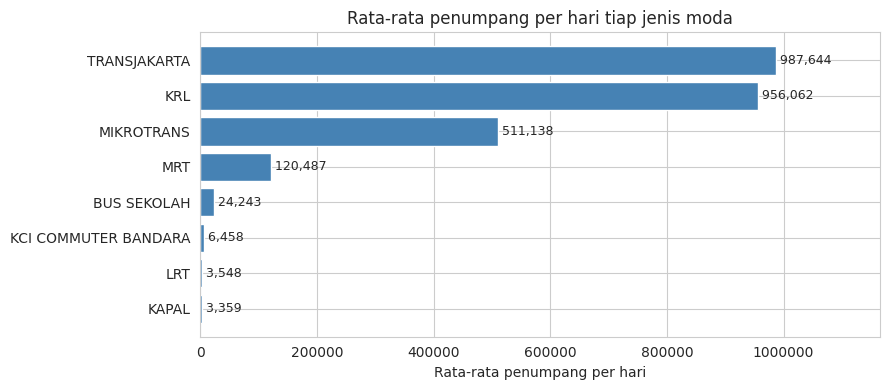

In [91]:
rata = df.groupby("jenis_moda")[kolom].mean().sort_values()
plt.figure(figsize=(9, 4))
plt.barh(rata.index, rata.values, color="steelblue")
for i, v in enumerate(rata.values):
    plt.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
plt.xlim(0, rata.max() * 1.18)
plt.ticklabel_format(style="plain", axis="x")
plt.xlabel("Rata-rata penumpang per hari")
plt.title("Rata-rata penumpang per hari tiap jenis moda")
plt.tight_layout()
plt.show()

- **Temuan:** Volume penumpang terkonsentrasi pada TransJakarta dan KRL.
- **Bukti:** Keduanya ≈ 1 juta/hari; MIKROTRANS ≈ 511 ribu, MRT ≈ 120 ribu; Bus Sekolah, KCI Bandara, LRT, dan Kapal hanya ribuan sampai puluhan ribu.
- **Interpretasi:** Ada tiga tingkat skala layanan: massal (TransJakarta, KRL, MIKROTRANS), menengah (MRT, Bus Sekolah), dan kecil/khusus (KCI Bandara, LRT, Kapal).
- **Implikasi:** Tanpa transformasi, jarak pada clustering didominasi TransJakarta dan KRL, sehingga perlu log dan scaling.

### B. Data Numerik - Histogram

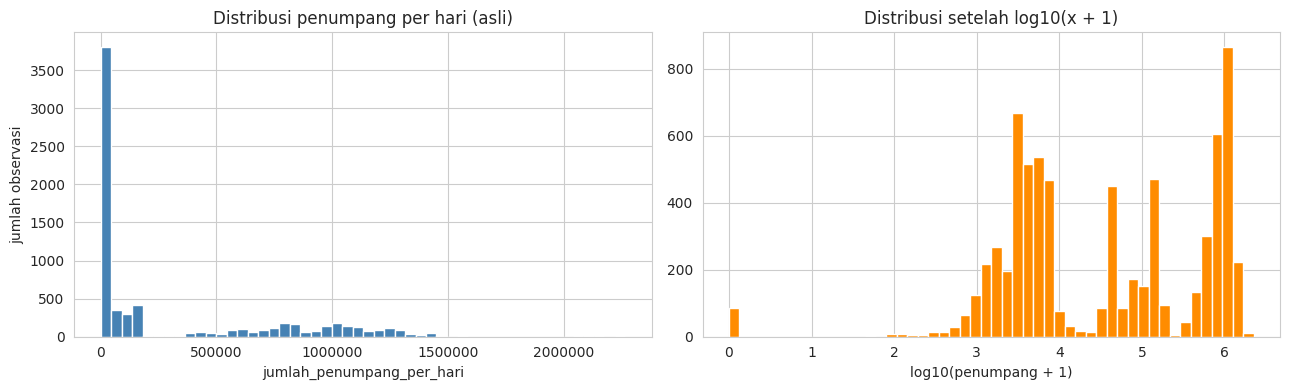

Skewness asli        : 1.19
Skewness setelah log : -0.48


In [92]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df[kolom], bins=50, color="steelblue")
ax[0].set_title("Distribusi penumpang per hari (asli)")
ax[0].set_xlabel("jumlah_penumpang_per_hari"); ax[0].set_ylabel("jumlah observasi")
ax[0].ticklabel_format(style="plain", axis="x")

ax[1].hist(np.log10(df[kolom] + 1), bins=50, color="darkorange")
ax[1].set_title("Distribusi setelah log10(x + 1)")
ax[1].set_xlabel("log10(penumpang + 1)")
plt.tight_layout()
plt.show()
print("Skewness asli        :", round(df[kolom].skew(), 2))
print("Skewness setelah log :", round(np.log10(df[kolom] + 1).skew(), 2))

- **Temuan:** Distribusi asli miring ke kanan dan memiliki beberapa puncak.
- **Bukti:** Skewness 1,19; sebagian besar observasi menumpuk di dekat nol, sebagian lain di 0,5-1,5 juta. Setelah log, skewness -0,48 dan terlihat beberapa gundukan terpisah.
- **Interpretasi:** Gundukan sesuai kelompok skala moda (kecil, menengah, massal); histogram gabungan adalah campuran beberapa populasi.
- **Implikasi:** Log diperlukan, dan distribusi dianalisis per moda.

### C. Data Numerik - Boxplot per Moda

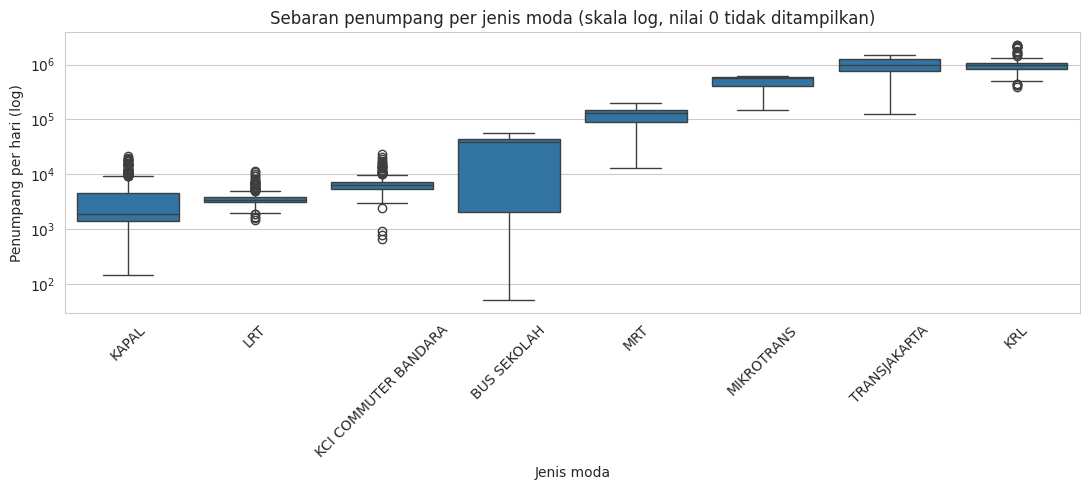

In [93]:
plt.figure(figsize=(11, 5))
urutan = df.groupby("jenis_moda")[kolom].median().sort_values().index
sns.boxplot(data=df[df[kolom] > 0], x="jenis_moda", y=kolom, order=urutan)
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Sebaran penumpang per jenis moda (skala log, nilai 0 tidak ditampilkan)")
plt.xlabel("Jenis moda"); plt.ylabel("Penumpang per hari (log)")
plt.tight_layout()
plt.show()

- **Temuan:** Naik-turunnya jumlah penumpang tiap hari berbeda-beda antarmoda.
- **Bukti:** Kotak Bus Sekolah dan Kapal paling lebar, artinya jumlah penumpangnya sering berubah. Kotak KRL, MRT, dan MIKROTRANS sempit, artinya jumlahnya relatif sama dari hari ke hari. Titik-titik di luar kotak (hari dengan lonjakan atau penurunan tak biasa) paling terlihat pada Kapal, LRT, KCI Bandara, dan KRL.
- **Interpretasi:** Moda untuk berangkat kerja cenderung stabil, sedangkan moda wisata atau layanan khusus lebih naik-turun.
- **Implikasi:** Tingkat kestabilan (CV) bisa dipakai untuk membedakan moda. Hari-hari lonjakan tidak dibuang karena itu pola yang memang terjadi.

### D. Waktu dan Jenis Layanan - Weekday vs Weekend

tipe_hari,Weekday,Weekend,rasio_weekend/weekday
jenis_moda,,,
BUS SEKOLAH,"41,201.50","1,405.00",0.03
MRT,"139,956.50","82,614.50",0.59
TRANSJAKARTA,"1,208,789.00","750,202.50",0.62
MIKROTRANS,"585,117.00","407,397.00",0.70
KCI COMMUTER BANDARA,"6,724.50","5,151.00",0.77
KRL,"1,024,636.00","785,786.50",0.77
LRT,"3,449.50","3,315.50",0.96
KAPAL,"1,651.50","5,516.50",3.34


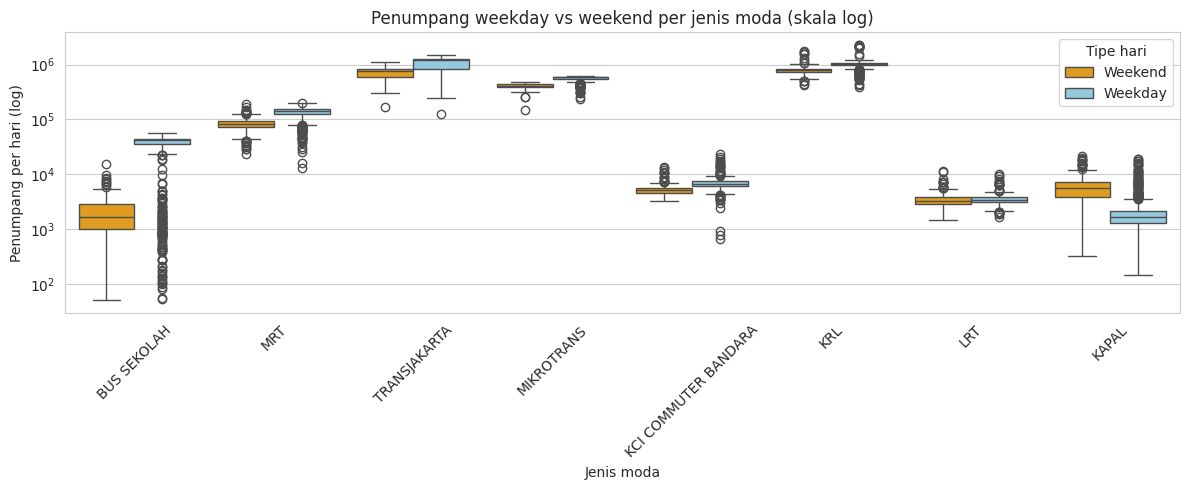

In [94]:
med = df.groupby(["jenis_moda", "tipe_hari"])[kolom].median().unstack()
med["rasio_weekend/weekday"] = (med["Weekend"] / med["Weekday"]).round(2)
display(med.sort_values("rasio_weekend/weekday"))

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df[kolom] > 0], x="jenis_moda", y=kolom, hue="tipe_hari",
            order=med.sort_values("rasio_weekend/weekday").index,
            palette={"Weekday": "skyblue", "Weekend": "orange"})
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Penumpang weekday vs weekend per jenis moda (skala log)")
plt.xlabel("Jenis moda"); plt.ylabel("Penumpang per hari (log)")
plt.legend(title="Tipe hari")
plt.tight_layout()
plt.show()

- **Temuan:** Ramai atau sepinya di akhir pekan berbeda tergantung jenis layanan.
- **Bukti:** Rasio penumpang akhir pekan dibanding hari kerja (median): Bus Sekolah 0,03; MRT 0,59; TransJakarta 0,62; MIKROTRANS 0,70; KRL & KCI Bandara 0,77; LRT 0,96; **Kapal 3,34**. Rasio di bawah 1 berarti lebih sepi di akhir pekan, di atas 1 berarti lebih ramai. Hanya Kapal yang lebih ramai di akhir pekan.
- **Interpretasi:** Ada tiga pola: (1) **komuter**, turun di akhir pekan; (2) **layanan sekolah**, hampir berhenti di akhir pekan; (3) **rekreasi**, naik di akhir pekan. LRT hampir sama saja antara hari kerja dan akhir pekan.
- **Implikasi:** Rasio ini paling jelas menangkap pengaruh waktu (hari kerja vs akhir pekan), jadi dipakai sebagai fitur clustering.

### E. Tren Bulanan per Moda

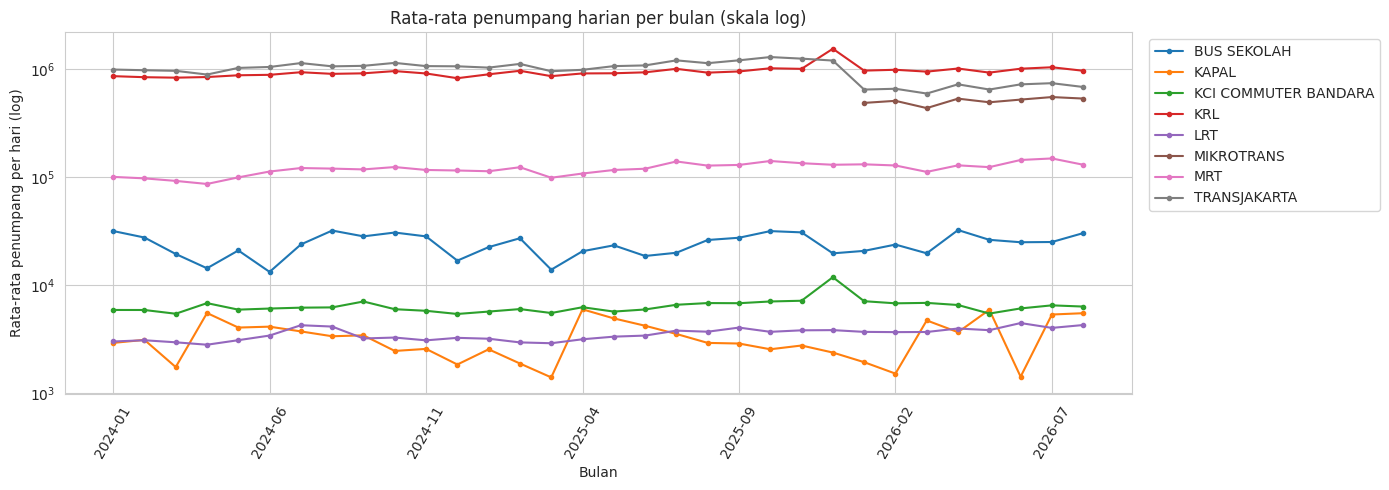

Rata-rata TransJakarta per tahun:


,rata_rata
tanggal,
2024,"1,043,917.00"
2025,"1,135,195.00"
2026,"681,256.00"


In [95]:
bulanan = df.pivot_table(index="bulan_tahun", columns="jenis_moda", values=kolom, aggfunc="mean")

fig, ax = plt.subplots(figsize=(14, 5))
bulanan.plot(ax=ax, marker="o", markersize=3)
ax.set_yscale("log")
ax.set_title("Rata-rata penumpang harian per bulan (skala log)")
ax.set_xlabel("Bulan"); ax.set_ylabel("Rata-rata penumpang per hari (log)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

tj = df[df["jenis_moda"] == "TRANSJAKARTA"]
print("Rata-rata TransJakarta per tahun:")
display(tj.groupby(tj["tanggal"].dt.year)[kolom].mean().round(0).to_frame("rata_rata"))



In [96]:
tj = df[df["jenis_moda"] == "TRANSJAKARTA"]
print(tj.groupby("bulan_tahun")[kolom].mean().round(0).loc["2025-10":"2026-03"])

bulan_tahun
2025-10   1,301,963.00
2025-11   1,258,973.00
2025-12   1,208,488.00
2026-01     650,845.00
2026-02     662,263.00
2026-03     598,039.00
Name: jumlah_penumpang_per_hari, dtype: float64


- **Temuan 1:** TransJakarta turun tajam mulai 2026.
  - **Bukti:** Rata-rata per hari ≈ 1,04 juta (2024), ≈ 1,14 juta (2025), ≈ 0,68 juta (2026), bersamaan dengan munculnya data MIKROTRANS (≈ 0,5 juta).
  - **Interpretasi:** Kemungkinan besar penumpang MIKROTRANS dulu dihitung sebagai TransJakarta, **lalu dicatat terpisah mulai 2026**. Jadi bukan penurunan penumpang yang sebenarnya.
  - **Implikasi:** Rata-rata TransJakarta seluruh periode menggabungkan dua cara pencatatan; dicatat sebagai keterbatasan.
- **Temuan 2:** KRL melonjak pada Desember 2025 (≈ 1,55 juta, dibanding ≈ 1 juta pada bulan lain).
  - **Implikasi:** Perlu dicek ke sumber data; sementara tetap dipertahankan.
- **Temuan 3:** Di luar dua hal itu, moda untuk berangkat kerja (KRL, MRT, TransJakarta) cukup stabil tiap bulan, sedangkan Kapal dan Bus Sekolah naik-turun mengikuti musim libur.

### F. Hubungan Antarvariabel - Scatter Plot Weekday vs Weekend per Moda

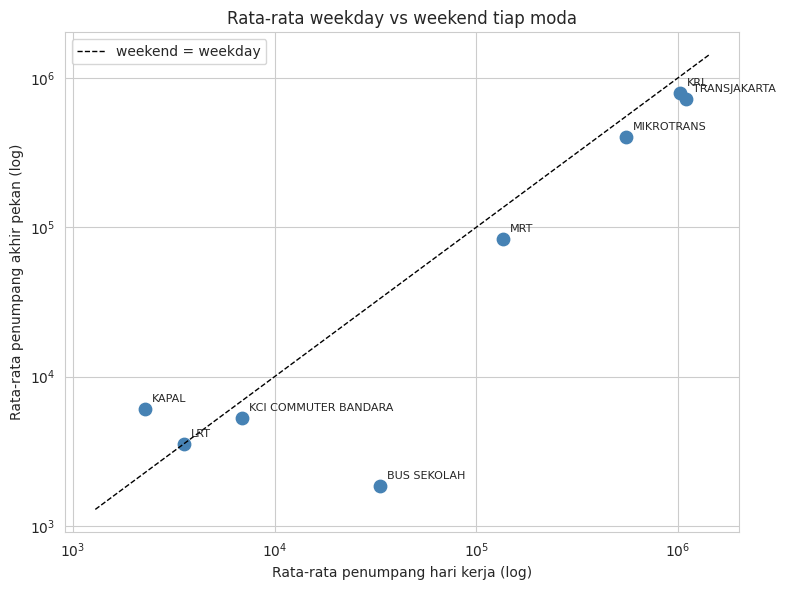

In [97]:
rata_tipe = df.groupby(["jenis_moda", "tipe_hari"])[kolom].mean().unstack()

plt.figure(figsize=(8, 6))
plt.scatter(rata_tipe["Weekday"], rata_tipe["Weekend"], s=80, color="steelblue")
for moda, baris in rata_tipe.iterrows():
    plt.annotate(moda, (baris["Weekday"], baris["Weekend"]), xytext=(5, 5),
                 textcoords="offset points", fontsize=8)
batas = [rata_tipe.min().min() * 0.7, rata_tipe.max().max() * 1.3]
plt.plot(batas, batas, "k--", lw=1, label="weekend = weekday")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Rata-rata penumpang hari kerja (log)")
plt.ylabel("Rata-rata penumpang akhir pekan (log)")
plt.title("Rata-rata weekday vs weekend tiap moda")
plt.legend()
plt.tight_layout()
plt.show()

- **Temuan:** Posisi moda terhadap garis diagonal (weekend = weekday) membedakan pola penggunaannya.
- **Bukti:** TransJakarta, KRL, MIKROTRANS, MRT, dan KCI Bandara berada **di bawah** garis (weekend lebih sepi), Bus Sekolah paling jauh di bawah, LRT hampir **tepat di garis** (weekend ≈ weekday), dan Kapal satu-satunya **di atas** garis (weekend lebih ramai).
- **Interpretasi:** Posisi sepanjang sumbu (skala penumpang) dan posisi terhadap garis (rasio weekend/weekday) sudah cukup untuk memisahkan moda ke beberapa kelompok.
- **Implikasi:** Mendukung pemakaian skala penumpang dan rasio weekend/weekday sebagai fitur clustering.

### G. Correlation Heatmap - Pola Harian Antarmoda

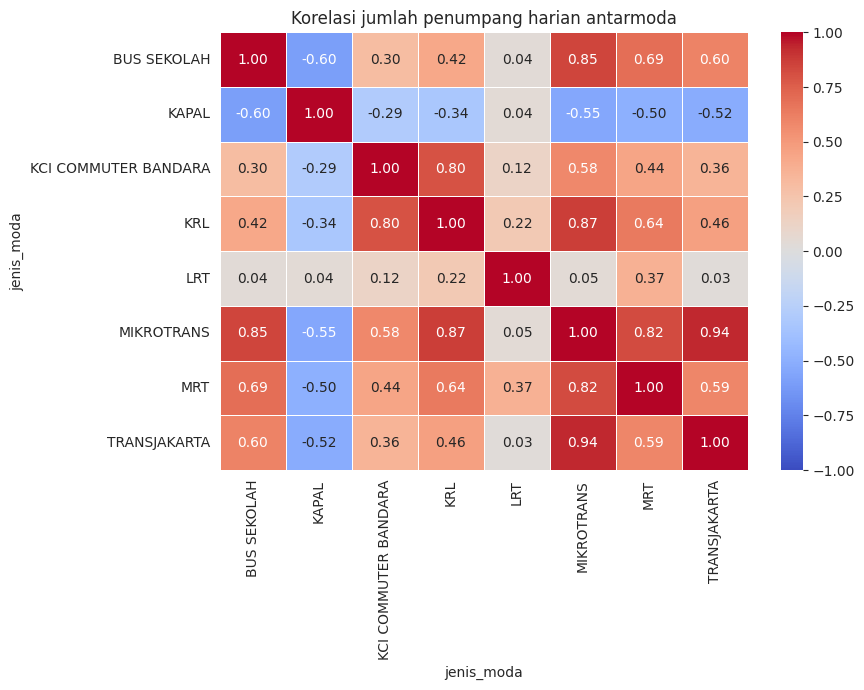

In [98]:
pivot_harian = df.pivot_table(index="tanggal", columns="jenis_moda", values=kolom)
korelasi = pivot_harian.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Korelasi jumlah penumpang harian antarmoda")
plt.tight_layout()
plt.show()



- **Temuan:** Moda untuk berangkat kerja ramai dan sepi bersamaan, sedangkan Kapal berlawanan.
- **Bukti:** Korelasi harian MRT-Bus Sekolah ≈ 0,69, TransJakarta-MRT ≈ 0,59, MIKROTRANS-TransJakarta ≈ 0,94 (periode 2026). Kapal berkorelasi **negatif** dengan Bus Sekolah (≈ -0,60), MRT (≈ -0,50), dan TransJakarta (≈ -0,52). LRT hampir tidak berkaitan dengan moda lain (kecuali lemah dengan MRT ≈ 0,37).
- **Interpretasi:** Di hari kerja dan hari sekolah, moda-moda ini ramai bersama. Di akhir pekan atau libur, Kapal ramai saat moda lain sepi.
- **Implikasi:** Pola waktu antarmoda memang berbeda, sehingga bisa menjadi dasar pengelompokan.

## 6. Temuan Kualitas Data

| No | Temuan | Bukti | Implikasi |
|---|---|---|---|
| 1 | **Perbedaan skala sangat besar** antarmoda | Rata-rata TransJakarta ≈ 987 ribu vs Kapal ≈ 3,4 ribu per hari | Clustering berbasis jarak akan didominasi moda besar → perlu log-transform dan scaling |
| 2 | **Distribusi miring dan memiliki beberapa puncak** | Skewness 1,19; histogram menunjukkan beberapa gundukan setelah log | Statistik gabungan menyesatkan → analisis per moda + transformasi log |
| 3 | **Nol yang mencurigakan pada KRL dan KCI Bandara** | Nilai 0 pada 16-17 Des 2024 (Senin-Selasa) | Kemungkinan data tidak tercatat → diperlakukan sebagai missing agar tidak menurunkan rata-rata dan menaikkan CV |
| 4 | **Outlier** pada Kapal, LRT, KCI Bandara, KRL | Tabel IQR; Kapal maks 21.846 (≈ 6× rata-rata), KRL > 2,1 juta pada Des 2025 | Outlier Kapal adalah pola libur yang nyata → dipertahankan dan tertangkap oleh fitur rasio dan CV; lonjakan KRL Desember 2025 dipertahankan sementara dan perlu diverifikasi |
| 5 | **Dugaan perubahan pencatatan TransJakarta/MIKROTRANS** | TJ turun dari ≈ 1,14 juta (2025) ke ≈ 0,68 juta (2026) saat MIKROTRANS muncul | TransJakarta (2024-2026) dan MIKROTRANS (hanya 2026) dihitung dari periode berbeda → dicatat sebagai keterbatasan dalam interpretasi cluster |

## 7. Rencana Preprocessing

Alur: **apa masalahnya → mengapa penting → bagaimana penanganannya.** Rencana ini dijalankan pada Minggu 3.

| Masalah | Variabel | Rencana Penanganan | Alasan |
|---|---|---|---|
| Missing value (nol mencurigakan) | `jumlah_penumpang_per_hari` (KRL, KCI Bandara, 16-17 Des 2024) | Ubah 0 menjadi NaN, sehingga tidak ikut dihitung saat agregasi per moda | Hanya 4 dari 7.061 baris; lebih jujur dikeluarkan daripada diisi nilai karangan |
| Outlier | `jumlah_penumpang_per_hari` (Kapal, KRL, LRT, KCI) | Tidak dihapus dan tidak diubah. Lonjakan Kapal dipertahankan sebagai pola libur dan ditangkap oleh fitur rasio weekend/weekday dan CV; lonjakan KRL Desember 2025 dipertahankan sementara karena belum terkonfirmasi ke penyedia data | Lonjakan libur adalah pola nyata yang ingin ditangkap clustering |
| Data kategorikal | `jenis_moda` | Tidak dijadikan fitur; dipakai sebagai identitas baris hasil agregasi | Setiap baris adalah satu moda, jadi label moda bukan fitur pembeda |
| Data waktu | `tanggal` | Diturunkan menjadi `is_weekend`, lalu dipakai untuk menghitung rasio weekend/weekday | Algoritma tidak bisa memakai tanggal mentah |
| Perbedaan skala | Semua fitur clustering | Log-transform untuk rata-rata penumpang saja, lalu `StandardScaler` untuk semua fitur | K-Means/Hierarchical berbasis jarak, semua fitur harus berkontribusi setara |

**Pencegahan data leakage:** clustering tidak memiliki target, sehingga tidak ada risiko kebocoran label. Yang dijaga adalah konsistensi: semua transformasi (log, scaling) dibungkus dalam satu `Pipeline` agar langkah yang sama dapat dijalankan ulang dan ditelusuri.

## 8. Rekayasa Fitur Awal

| Kandidat Fitur | Dibentuk dari | Alasan |
|---|---|---|
| **Fitur 1: `log_rata_penumpang`** | `log1p(rata-rata penumpang harian)` per moda | Menggambarkan **skala layanan** (massal/menengah/kecil) dengan meredam perbedaan skala antarmoda yang sangat besar |
| **Fitur 2: `rasio_weekend_weekday`** | rata-rata penumpang akhir pekan ÷ rata-rata hari kerja per moda | Menangkap aspek **waktu**: < 1 lebih sepi di akhir pekan (komuter atau sekolah), ≈ 1 netral, > 1 lebih ramai di akhir pekan (rekreasi) |
| **Fitur 3: `cv_harian`** | std ÷ mean penumpang harian per moda | Mengukur **kestabilan** penggunaan; bebas skala sehingga moda kecil dan besar bisa dibandingkan |



In [99]:
fitur_moda = df.groupby("jenis_moda").agg(
    jumlah_hari=(kolom, "count"),
    rata_penumpang=(kolom, "mean"),
    std_penumpang=(kolom, "std"),
)
fitur_moda["rata_weekday"] = df[df["is_weekend"] == 0].groupby("jenis_moda")[kolom].mean()
fitur_moda["rata_weekend"] = df[df["is_weekend"] == 1].groupby("jenis_moda")[kolom].mean()

fitur_moda["log_rata_penumpang"]    = np.log1p(fitur_moda["rata_penumpang"])
fitur_moda["rasio_weekend_weekday"] = fitur_moda["rata_weekend"] / fitur_moda["rata_weekday"]
fitur_moda["cv_harian"]             = fitur_moda["std_penumpang"] / fitur_moda["rata_penumpang"]

fitur_cluster = ["log_rata_penumpang", "rasio_weekend_weekday", "cv_harian"]
display(fitur_moda[fitur_cluster].sort_values("rasio_weekend_weekday").round(3))


,log_rata_penumpang,rasio_weekend_weekday,cv_harian
jenis_moda,,,
BUS SEKOLAH,10.10,0.06,0.84
MRT,11.70,0.61,0.30
TRANSJAKARTA,13.80,0.66,0.30
MIKROTRANS,13.14,0.72,0.20
KCI COMMUTER BANDARA,8.77,0.77,0.29
KRL,13.77,0.78,0.22
LRT,8.17,0.99,0.25
KAPAL,8.12,2.67,0.97


**Hasil awal:**
- `rasio_weekend_weekday` membedakan empat pola dengan jelas: Bus Sekolah (≈ 0,06, hampir berhenti di akhir pekan), moda untuk berangkat kerja (≈ 0,6-0,8, turun di akhir pekan), LRT (≈ 0,99, hampir sama), dan Kapal (≈ 2,67, lebih ramai di akhir pekan).
- `log_rata_penumpang` membedakan tiga tingkat skala: besar (TransJakarta, KRL, MIKROTRANS ≈ 13-14), menengah (MRT ≈ 11,7; Bus Sekolah ≈ 10), dan kecil (KCI Bandara, LRT, Kapal ≈ 8-9).
- `cv_harian` tinggi pada Kapal (≈ 0,97) dan Bus Sekolah (≈ 0,84), artinya jumlah penumpangnya sering naik-turun. Nilainya rendah pada moda untuk berangkat kerja (≈ 0,2-0,3), artinya relatif stabil.

**Dampak yang diharapkan:** ketiga fitur membuat pengelompokan didasarkan pada skala, pola waktu, dan kestabilan penggunaan, bukan pada jumlah penumpang mentah yang didominasi moda besar.

---
# MINGGU 3
## Preprocessing → Baseline → Evaluasi Awal

## A. Preprocessing

Langkah preprocessing dijalankan sesuai rencana Minggu 2:

| No | Langkah | Alasan |
|---|---|---|
| 1 | Nol pada KRL & KCI Bandara (16-17 Des 2024) → NaN | Bukan nol sebenarnya; jika dibiarkan akan menurunkan rata-rata dan menaikkan CV |
| 2 | Buat fitur waktu `is_weekend` dari `tanggal` | Diperlukan untuk menghitung rasio weekend/weekday |
| 3 | Agregasi data harian → 1 baris per moda + bentuk fitur | Unit analisis adalah moda |
| 4 | Outlier tidak dihapus | Lonjakan libur (mis. Kapal saat Lebaran) adalah pola nyata yang ingin ditangkap |
| 5 | Encoding tidak dilakukan | `jenis_moda` adalah identitas baris setelah agregasi, bukan fitur |
| 6 | Log-transform `rata_penumpang` + `StandardScaler` semua fitur, dalam `Pipeline` | K-Means berbasis jarak; tanpa ini fitur skala akan mendominasi |

**Catatan:** Tidak ada train-test split karena clustering tidak memiliki target dan datanya hanya 8 moda. Nama moda (`jenis_moda`) tidak dipakai sebagai fitur, jadi pengelompokan hanya berdasarkan pola penumpang.

### Langkah 1 - Menangani nilai nol yang mencurigakan

In [100]:
df_clean = df.copy()
mask_missing = (df_clean[kolom] == 0) & df_clean["jenis_moda"].isin(["KRL", "KCI COMMUTER BANDARA"])
display(df_clean.loc[mask_missing, ["tanggal", "jenis_moda", kolom]])

df_clean.loc[mask_missing, kolom] = np.nan
print("Jumlah nilai yang diubah menjadi NaN:", mask_missing.sum())
print("Sisa nilai 0 (hanya Bus Sekolah):", (df_clean[kolom] == 0).groupby(df_clean["jenis_moda"]).sum()
      .loc[lambda s: s > 0].to_dict())

,tanggal,jenis_moda,jumlah_penumpang_per_hari
2641,2024-12-16,KRL,0
2642,2024-12-17,KRL,0
2734,2024-12-16,KCI COMMUTER BANDARA,0
2735,2024-12-17,KCI COMMUTER BANDARA,0


Jumlah nilai yang diubah menjadi NaN: 4
Sisa nilai 0 (hanya Bus Sekolah): {'BUS SEKOLAH': 82}


4 nilai nol (KRL dan KCI Bandara, 16-17 Des 2024) diubah menjadi NaN dan tidak diisi. Saat menghitung, pandas otomatis melewati NaN, jadi KRL dan KCI Bandara dihitung dari 972 hari yang valid. Nol pada Bus Sekolah tetap dipakai karena memang wajar (libur sekolah).

### Langkah 2 - Fitur waktu, agregasi per moda, dan pembentukan fitur

In [101]:
df_clean["is_weekend"] = (df_clean["tanggal"].dt.dayofweek >= 5).astype(int)

grup = df_clean.groupby("jenis_moda")[kolom]
data_moda = pd.DataFrame({
    "jumlah_hari_valid": grup.count(),
    "rata_penumpang": grup.mean(),
    "rata_weekday": df_clean[df_clean["is_weekend"] == 0].groupby("jenis_moda")[kolom].mean(),
    "rata_weekend": df_clean[df_clean["is_weekend"] == 1].groupby("jenis_moda")[kolom].mean(),
    "cv_harian": grup.std() / grup.mean(),
})
data_moda["rasio_weekend_weekday"] = data_moda["rata_weekend"] / data_moda["rata_weekday"]

fitur = ["rata_penumpang", "rasio_weekend_weekday", "cv_harian"]
display(data_moda)
print("NaN pada fitur:", int(data_moda[fitur].isna().sum().sum()))

data_moda.reset_index().to_csv("fitur_moda.csv", index=False)
print("Tabel fitur disimpan ke fitur_moda.csv")

,jumlah_hari_valid,rata_penumpang,rata_weekday,rata_weekend,cv_harian,rasio_weekend_weekday
jenis_moda,,,,,,
BUS SEKOLAH,974,"24,242.98","33,188.56","1,846.85",0.84,0.06
KAPAL,974,"3,359.05","2,272.60","6,079.10",0.97,2.67
KCI COMMUTER BANDARA,972,"6,471.32","6,930.87","5,324.11",0.28,0.77
KRL,972,"958,029.14","1,022,377.88","797,388.75",0.21,0.78
LRT,974,"3,547.85","3,555.25","3,529.33",0.25,0.99
MIKROTRANS,243,"511,137.89","555,276.60","402,052.23",0.20,0.72
MRT,974,"120,487.16","135,442.53","83,044.94",0.30,0.61
TRANSJAKARTA,974,"987,643.73","1,094,258.71","720,722.77",0.30,0.66


NaN pada fitur: 0
Tabel fitur disimpan ke fitur_moda.csv


### Langkah 3 - Log-transform dan scaling dalam Pipeline

In [102]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

preprocessor = ColumnTransformer([
    ("log_skala", Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scaler", StandardScaler()),
    ]), ["rata_penumpang"]),
    ("skala", StandardScaler(), ["rasio_weekend_weekday", "cv_harian"]),
])

X = preprocessor.fit_transform(data_moda[fitur])
nama_fitur = ["log_rata_penumpang", "rasio_weekend_weekday", "cv_harian"]
X_df = pd.DataFrame(X, columns=nama_fitur, index=data_moda.index)

print("Data setelah preprocessing (siap clustering):")
display(X_df)
display(X_df.describe().loc[["mean", "std", "min", "max"]])

Data setelah preprocessing (siap clustering):


,log_rata_penumpang,rasio_weekend_weekday,cv_harian
jenis_moda,,,
BUS SEKOLAH,-0.37,-1.19,1.49
KAPAL,-1.22,2.48,1.93
KCI COMMUTER BANDARA,-0.94,-0.20,-0.49
KRL,1.22,-0.18,-0.73
LRT,-1.20,0.12,-0.59
MIKROTRANS,0.95,-0.26,-0.77
MRT,0.33,-0.41,-0.42
TRANSJAKARTA,1.24,-0.35,-0.42


,log_rata_penumpang,rasio_weekend_weekday,cv_harian
mean,-0.00,0.00,0.00
std,1.07,1.07,1.07
min,-1.22,-1.19,-0.77
max,1.24,2.48,1.93


**Data setelah preprocessing:** 8 moda × 3 fitur. Setiap kolom sekarang punya rata-rata 0 dan sebaran ≈ 1 (angka 1,07 pada tabel `describe` hanya beda rumus hitung dengan `StandardScaler`), sehingga ketiga fitur berpengaruh setara pada jarak K-Means. Tanpa log dan scaling, K-Means hampir hanya melihat jumlah penumpang (3 ribu - 988 ribu), bukan pola akhir pekan dan kestabilan (0,2 - 1,0).

**Arti nilainya** (0 = rata-rata semua moda, positif = di atas, negatif = di bawah):
- **`log_rata_penumpang`:** TransJakarta, KRL, dan MIKROTRANS tertinggi (penumpang terbanyak); Kapal, LRT, dan KCI Bandara terendah.
- **`rasio_weekend_weekday`:** Kapal paling tinggi (≈ 2,5) karena hanya Kapal yang lebih ramai di akhir pekan; Bus Sekolah paling rendah (≈ -1,2) karena hampir berhenti di akhir pekan.
- **`cv_harian`:** Kapal (≈ 1,9) dan Bus Sekolah (≈ 1,5) tinggi karena sering naik-turun; moda lain lebih stabil.

### Pembagian data dan pencegahan data leakage

**Tidak dilakukan train-test split**, dengan alasan:
1. Clustering tidak memiliki target, sehingga tidak ada "jawaban benar" yang perlu diuji pada data test.
2. Tujuan analisis adalah **mendeskripsikan** pengelompokan 8 moda yang ada, bukan memprediksi data baru.
3. Data hanya 8 baris; jika dibagi, sebagian moda tidak ikut dikelompokkan.

**Pencegahan data leakage:**
- Tidak ada target yang dapat bocor ke fitur.
- `jenis_moda` tidak dipakai sebagai fitur, sehingga cluster tidak "dibocorkan" oleh label moda.
- Semua transformasi (log dan scaling) berada dalam satu `ColumnTransformer`/`Pipeline`, sehingga langkah yang sama dapat dijalankan ulang secara konsisten.

## B. Baseline

**Algoritma baseline:** K-Means dengan konfigurasi awal, sesuai panduan untuk project unsupervised.

| Parameter | Nilai | Alasan |
|---|---|---|
| `n_clusters` | 3 | Dari EDA Minggu 2 terlihat 3 pola: komuter (turun di akhir pekan), rekreasi (naik di akhir pekan), dan layanan sekolah (hampir berhenti di akhir pekan). Nilai ini belum dioptimasi. |
| `n_init` | 10 | K-Means dijalankan 10 kali dengan titik awal berbeda, lalu diambil hasil terbaik |
| `random_state` | 42 | Agar hasil dapat direproduksi |

In [103]:
from sklearn.cluster import KMeans

baseline = KMeans(n_clusters=3, n_init=10, random_state=42)
baseline.fit(X)                      # proses training
label_asli = baseline.labels_

# Penomoran cluster diurutkan dari rata-rata penumpang terbesar agar mudah dibaca (0 = skala terbesar)
urutan = (pd.Series(data_moda["rata_penumpang"].values).groupby(label_asli).mean()
          .sort_values(ascending=False).index)
peta = {lama: baru for baru, lama in enumerate(urutan)}
data_moda["cluster"] = [peta[l] for l in label_asli]

print("Inertia (jumlah jarak kuadrat ke pusat cluster):", round(baseline.inertia_, 3))
print("Hasil pengelompokan (prediksi cluster tiap moda):")
display(data_moda[["cluster"]].sort_values("cluster"))

Inertia (jumlah jarak kuadrat ke pusat cluster): 4.738
Hasil pengelompokan (prediksi cluster tiap moda):


,cluster
jenis_moda,
KRL,0
TRANSJAKARTA,0
MRT,0
MIKROTRANS,0
BUS SEKOLAH,1
KCI COMMUTER BANDARA,1
LRT,1
KAPAL,2


## C. Evaluasi Awal

Metrik yang digunakan sesuai panduan unsupervised: **jumlah cluster, ukuran setiap cluster, karakteristik cluster, dan silhouette score**.

- **Silhouette score** (-1 sampai 1) mengukur seberapa dekat suatu moda dengan anggota cluster-nya dibandingkan dengan cluster terdekat lain. Mendekati 1 = terpisah jelas; sekitar 0 = berada di perbatasan; negatif = kemungkinan salah cluster.
- Silhouette juga dihitung **per moda** untuk melihat anggota mana yang kurang cocok dengan cluster-nya.

In [104]:
from sklearn.metrics import silhouette_score, silhouette_samples

label = data_moda["cluster"].values
print("Jumlah cluster  :", data_moda["cluster"].nunique())
print("Silhouette score:", round(silhouette_score(X, label), 3))

data_moda["silhouette_moda"] = silhouette_samples(X, label)

ringkasan = data_moda.groupby("cluster").agg(
    ukuran=("rata_penumpang", "size"),
    anggota=("rata_penumpang", lambda s: ", ".join(s.index)),
    rata_penumpang=("rata_penumpang", "mean"),
    rasio_weekend_weekday=("rasio_weekend_weekday", "mean"),
    cv_harian=("cv_harian", "mean"),
    silhouette_rata=("silhouette_moda", "mean"),
)
print("Ukuran dan karakteristik setiap cluster (fitur dalam skala asli):")
display(ringkasan)

print("Silhouette per moda:")
display(data_moda[["cluster", "silhouette_moda"]].sort_values(["cluster", "silhouette_moda"]))

Jumlah cluster  : 3
Silhouette score: 0.435
Ukuran dan karakteristik setiap cluster (fitur dalam skala asli):


,ukuran,anggota,rata_penumpang,rasio_weekend_weekday,cv_harian,silhouette_rata
cluster,,,,,,
0,4,"KRL, MIKROTRANS, MRT, TRANSJAKARTA","644,324.48",0.69,0.25,0.70
1,3,"BUS SEKOLAH, KCI COMMUTER BANDARA, LRT","11,420.72",0.61,0.46,0.22
2,1,KAPAL,"3,359.05",2.67,0.97,0.00


Silhouette per moda:


,cluster,silhouette_moda
jenis_moda,,
MRT,0,0.48
TRANSJAKARTA,0,0.76
MIKROTRANS,0,0.78
KRL,0,0.79
BUS SEKOLAH,1,0.07
KCI COMMUTER BANDARA,1,0.28
LRT,1,0.31
KAPAL,2,0.00


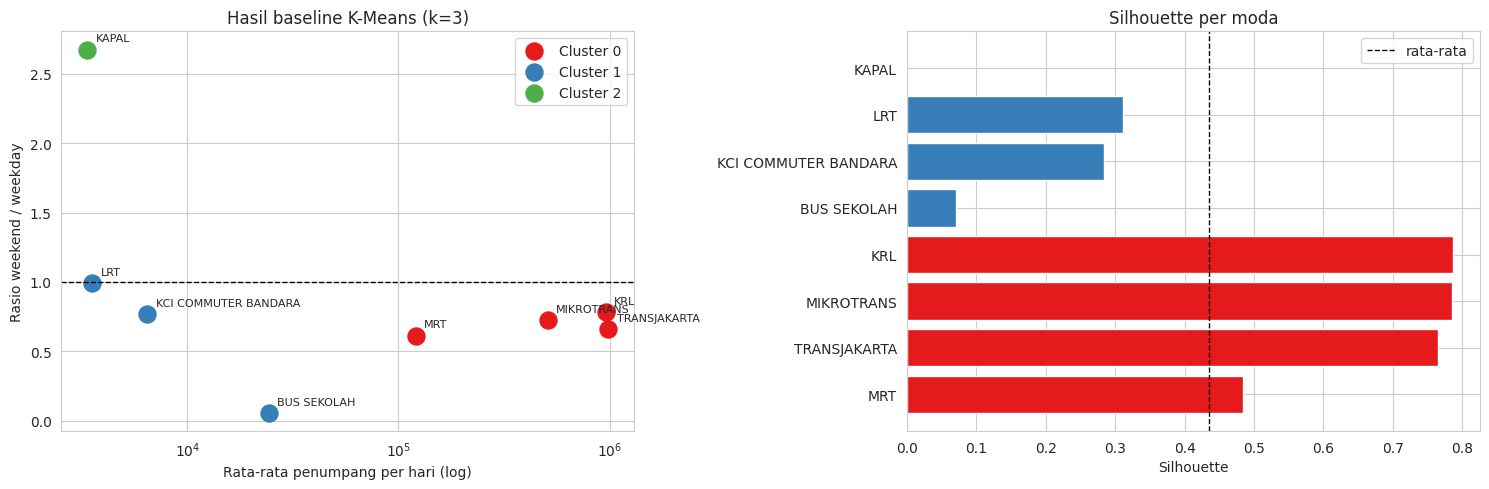

In [105]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

warna = sns.color_palette("Set1", 3)
for c in sorted(data_moda["cluster"].unique()):
    sub = data_moda[data_moda["cluster"] == c]
    ax[0].scatter(sub["rata_penumpang"], sub["rasio_weekend_weekday"], s=150,
                  color=warna[c], label=f"Cluster {c}")
for moda, baris in data_moda.iterrows():
    ax[0].annotate(moda, (baris["rata_penumpang"], baris["rasio_weekend_weekday"]),
                   xytext=(6, 6), textcoords="offset points", fontsize=8)
ax[0].axhline(1, ls="--", c="k", lw=1)
ax[0].set_xscale("log")
ax[0].set_xlabel("Rata-rata penumpang per hari (log)")
ax[0].set_ylabel("Rasio weekend / weekday")
ax[0].set_title("Hasil baseline K-Means (k=3)")
ax[0].legend()

urut = data_moda.sort_values(["cluster", "silhouette_moda"])
ax[1].barh(urut.index, urut["silhouette_moda"], color=[warna[c] for c in urut["cluster"]])
ax[1].axvline(silhouette_score(X, label), ls="--", c="k", lw=1, label="rata-rata")
ax[1].set_xlabel("Silhouette")
ax[1].set_title("Silhouette per moda")
ax[1].legend()
plt.tight_layout()
plt.show()

In [106]:
# Cek stabilitas: apakah hasil berubah jika titik awal K-Means berbeda?
from sklearn.metrics import adjusted_rand_score

stabilitas = []
for rs in [0, 1, 7, 21, 99]:
    lab = KMeans(n_clusters=3, n_init=10, random_state=rs).fit_predict(X)
    stabilitas.append({"random_state": rs,
                       "silhouette": round(silhouette_score(X, lab), 3),
                       "kesamaan_dgn_baseline (ARI)": round(adjusted_rand_score(label, lab), 3)})
display(pd.DataFrame(stabilitas))

,random_state,silhouette,kesamaan_dgn_baseline (ARI)
0,0,0.43,1.00
1,1,0.43,1.00
2,7,0.43,1.00
3,21,0.43,1.00
4,99,0.43,1.00


**Interpretasi singkat:**

| Cluster | Anggota | Ciri utama | Arti |
|---|---|---|---|
| 0 | KRL, MIKROTRANS, MRT, TransJakarta | Penumpang banyak, turun di akhir pekan, stabil | **Komuter massal** |
| 1 | Bus Sekolah, KCI Bandara, LRT | Penumpang sedikit, pola waktu berbeda-beda | **Campuran skala kecil** |
| 2 | Kapal | Penumpang sedikit, naik di akhir pekan, paling fluktuatif | **Rekreasi** |

**Hasil evaluasi:**
- Silhouette keseluruhan **0,435**: pengelompokan sudah terlihat, tetapi belum terpisah tegas.
- Cluster 0 paling solid (silhouette ≈ 0,76-0,79).
- Bus Sekolah paling lemah (≈ 0,07) karena sebenarnya tidak mirip LRT dan KCI Bandara.
- Kapal bernilai 0 karena sendirian di clusternya (aturan silhouette).
- Hasil **stabil**: random_state berbeda tetap menghasilkan kelompok yang sama (ARI = 1).

**Kesimpulan:** Baseline sudah memisahkan **komuter massal** dan **rekreasi (Kapal)**. Namun **Bus Sekolah** belum terpisah. Ia tergabung dengan LRT dan KCI Bandara hanya karena sama-sama berpenumpang sedikit, padahal pola waktunya sangat berbeda (hampir berhenti di akhir pekan).

## D. Temuan Awal

**Apa yang berhasil?**
- Preprocessing berjalan sesuai rencana: 4 nilai nol mencurigakan ditangani dan semua fitur sudah setara skalanya (log + scaling).
- Baseline K-Means memisahkan **komuter massal** (KRL, MIKROTRANS, MRT, TransJakarta) dan **rekreasi** (Kapal) dengan jelas.
- Hasil stabil: 5 random_state berbeda menghasilkan kelompok yang sama (ARI = 1).

**Apa masalah yang ditemukan?**
- Bus Sekolah tergabung dengan LRT dan KCI Bandara (silhouette ≈ 0,07), padahal pola akhir pekannya sangat berbeda (rasio 0,06 vs 0,99).
- Ukuran cluster tidak seimbang (4 - 3 - 1) karena Kapal sendirian.
- Data TransJakarta dan MIKROTRANS berasal dari periode berbeda (2024-2026 vs 2026), sehingga posisi keduanya bisa terpengaruh.

**Apa kelemahan baseline?**
- Nilai k = 3 hanya dari intuisi EDA dan belum dibandingkan dengan k lain.
- K-Means kurang cocok untuk data kecil yang punya satu titik ekstrem (Kapal).
- Dengan hanya 8 moda, silhouette mudah berubah karena satu moda saja.
- Fitur skala penumpang terlalu dominan, sehingga pola waktu Bus Sekolah tertutupi.

**Apa yang perlu diperbaiki berikutnya?**
- Coba beberapa nilai k dan nilai dengan Elbow method dan silhouette.
- Tambahkan Agglomerative Clustering sebagai pembanding.
- Periksa apakah posisi Bus Sekolah berubah jika pola waktu lebih diperhatikan.

---
# MINGGU 4
## Dari Baseline Menuju Kandidat Model & Perbandingan Awal



### A. Kandidat Model dan Metrik Evaluasi

| Model | Konfigurasi | Alasan pemilihan |
|---|---|---|
| **Baseline** | K-Means, k = 3 | Konfigurasi awal dari Minggu 3 |
| **Kandidat 1** | K-Means, k = 2 sampai 6 | k = 3 dipilih dari intuisi EDA dan belum diuji; perlu bukti nilai k yang paling sesuai |
| **Kandidat 2** | Agglomerative Clustering (linkage Ward), k = 2 sampai 6 | Tidak bergantung pada titik awal acak dan cocok untuk data kecil; dendrogram memperlihatkan urutan penggabungan moda. Ward meminimalkan varians dalam cluster seperti K-Means, sehingga hasilnya sebanding |
| **Kandidat 3** | Gaussian Mixture (covariance diag), k = 2 sampai 6 | Model berbasis probabilitas, berbeda dari pendekatan berbasis jarak pada K-Means dan Ward. Covariance diag dipilih karena datanya hanya 8 moda |
| **Kandidat 4** | Agglomerative (linkage average dan complete), k = 2 sampai 6 | Menguji apakah hasil Ward bergantung pada jenis linkage |

Selain model, dilakukan analisis sensitivitas fitur pada bagian E.

| Metrik | Arti | Arah lebih baik |
|---|---|---|
| Silhouette score | Seberapa jelas setiap moda terpisah dari cluster lain | Lebih tinggi (maks 1) |
| Davies-Bouldin index | Rata-rata kemiripan cluster dengan cluster terdekatnya | Lebih rendah |
| Calinski-Harabasz index | Rasio jarak antar-cluster terhadap jarak dalam cluster | Lebih tinggi |
| Inertia (khusus K-Means) | Jumlah jarak kuadrat ke pusat cluster, untuk Elbow method | Dilihat titik "siku" |
| Adjusted Rand Index (ARI) | Kesamaan dua hasil pengelompokan (antarmodel atau antarvariasi fitur); bukan penilai kualitas cluster | Mendekati 1 berarti pengelompokan sama |

### B. Eksperimen Beberapa Nilai K (K-Means dan Agglomerative)

In [107]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

def anggota_cluster(lab):
    return " | ".join(", ".join(data_moda.index[lab == c]) for c in np.unique(lab))

hasil_k = []
label_model = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    label_model[("K-Means", k)] = km.labels_
    label_model[("Agglomerative", k)] = ag
    for nama, lab in [("K-Means", km.labels_), ("Agglomerative", ag)]:
        hasil_k.append({
            "model": nama, "k": k,
            "silhouette": silhouette_score(X, lab),
            "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab),
            "inertia": km.inertia_ if nama == "K-Means" else np.nan,
            "ukuran_cluster": sorted(np.bincount(lab), reverse=True),
        })
hasil_k = pd.DataFrame(hasil_k)
display(hasil_k)

,model,k,silhouette,davies_bouldin,calinski_harabasz,inertia,ukuran_cluster
0,K-Means,2,0.50,0.30,7.05,11.04,"[7, 1]"
1,Agglomerative,2,0.50,0.30,7.05,NaN,"[7, 1]"
2,K-Means,3,0.44,0.62,10.16,4.74,"[4, 3, 1]"
3,Agglomerative,3,0.44,0.62,10.16,NaN,"[4, 3, 1]"
4,K-Means,4,0.53,0.20,39.93,0.78,"[4, 2, 1, 1]"
5,Agglomerative,4,0.53,0.20,39.93,NaN,"[4, 2, 1, 1]"
6,K-Means,5,0.39,0.17,78.60,0.23,"[3, 2, 1, 1, 1]"
7,Agglomerative,5,0.39,0.17,78.60,NaN,"[3, 2, 1, 1, 1]"
8,K-Means,6,0.25,0.20,73.64,0.13,"[2, 2, 1, 1, 1, 1]"
9,Agglomerative,6,0.25,0.20,73.64,NaN,"[2, 2, 1, 1, 1, 1]"


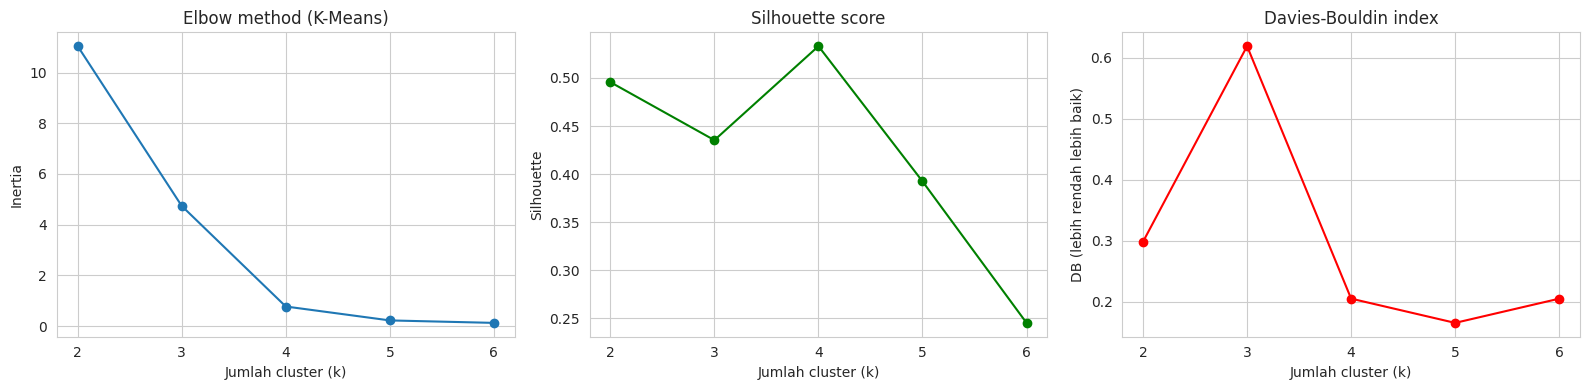

In [108]:
km_k = hasil_k[hasil_k["model"] == "K-Means"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(km_k["k"], km_k["inertia"], marker="o")
ax[0].set_title("Elbow method (K-Means)"); ax[0].set_ylabel("Inertia")
ax[1].plot(km_k["k"], km_k["silhouette"], marker="o", color="green")
ax[1].set_title("Silhouette score"); ax[1].set_ylabel("Silhouette")
ax[2].plot(km_k["k"], km_k["davies_bouldin"], marker="o", color="red")
ax[2].set_title("Davies-Bouldin index"); ax[2].set_ylabel("DB (lebih rendah lebih baik)")
for a in ax:
    a.set_xlabel("Jumlah cluster (k)"); a.set_xticks(range(2, 7))
plt.tight_layout()
plt.show()

**Interpretasi:**
- **Elbow:** inertia turun tajam dari k = 2 (≈ 11,0) ke k = 3 (≈ 4,7) dan k = 4 (≈ 0,8), lalu hampir datar. Siku ada di **k = 4**.
- **Silhouette:** tertinggi di **k = 4 (0,533)**, disusul k = 2 (0,496) dan baseline k = 3 (0,435), lalu turun di k = 5-6.
- k = 2 hanya memisahkan Kapal dari 7 moda lain (7-1), sehingga kurang informatif untuk tujuan project.
- **Davies-Bouldin** dan **Calinski-Harabasz** terus membaik sampai k = 5. Dengan hanya 8 moda, keduanya cenderung memilih k besar karena cluster kecil (1-2 anggota) otomatis terlihat rapat. Karena itu keduanya hanya pendukung, bukan penentu.

**Kesimpulan:** k = 4 dipilih karena Elbow dan silhouette sama-sama menunjuk ke sana.

### C. Kandidat 2 - Agglomerative Clustering (Dendrogram)

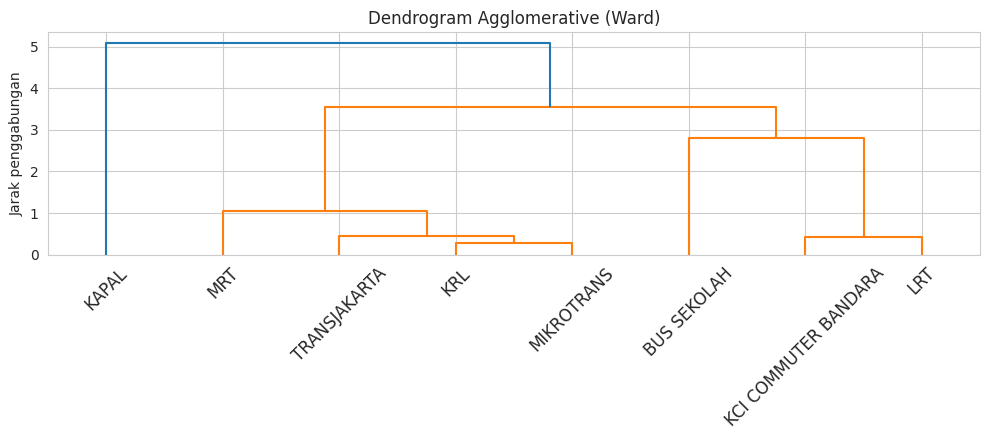

,k,ARI K-Means vs Agglomerative
0,2,1.00
1,3,1.00
2,4,1.00
3,5,1.00
4,6,1.00


In [109]:
from scipy.cluster.hierarchy import linkage, dendrogram

plt.figure(figsize=(10, 4.5))
dendrogram(linkage(X, method="ward"), labels=data_moda.index.tolist(), leaf_rotation=45)
plt.title("Dendrogram Agglomerative (Ward)")
plt.ylabel("Jarak penggabungan")
plt.tight_layout()
plt.show()

# Apakah Agglomerative memberi pengelompokan yang sama dengan K-Means?
kesamaan = pd.DataFrame({
    "k": list(range(2, 7)),
    "ARI K-Means vs Agglomerative": [adjusted_rand_score(label_model[("K-Means", k)], label_model[("Agglomerative", k)])
                                     for k in range(2, 7)],
})
display(kesamaan)

**Interpretasi:** Pada dendrogram, moda yang paling mirip bergabung lebih dulu: KRL dan MIKROTRANS, lalu TransJakarta, lalu MRT (jarak ≤ 1,1), serta LRT dan KCI Bandara (≈ 0,4). Bus Sekolah baru bergabung dengan LRT-KCI pada jarak jauh lebih besar (≈ 2,8), dan Kapal bergabung paling akhir (≈ 5,1). Artinya Kapal paling berbeda dari moda lain, disusul Bus Sekolah. Jika dendrogram dipotong di antara jarak 1,1 dan 2,8, hasilnya 4 cluster. Untuk semua nilai k, hasil Agglomerative **sama persis** dengan K-Means (ARI = 1).

### D. Model Pembanding Tambahan (GMM dan Linkage Lain)

Pada bagian B dan C, Agglomerative Ward menghasilkan pengelompokan yang sama dengan K-Means di semua k. Agar perbandingan lebih berarti, ditambahkan dua pembanding: Agglomerative dengan linkage average dan complete (Kandidat 4), serta Gaussian Mixture (Kandidat 3). `covariance_type="diag"` dipilih karena datanya hanya 8 moda, sehingga covariance penuh tidak stabil.

In [110]:
from sklearn.mixture import GaussianMixture

hasil_tambahan = []
for k in range(2, 7):
    model_lain = {
        "Agglomerative (average)":  AgglomerativeClustering(n_clusters=k, linkage="average").fit_predict(X),
        "Agglomerative (complete)": AgglomerativeClustering(n_clusters=k, linkage="complete").fit_predict(X),
        # covariance diag dipakai karena hanya 8 titik; full covariance tidak stabil
        "GMM (diag)": GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-3,
                                      n_init=10, random_state=42).fit_predict(X),
    }
    for nama, lab in model_lain.items():
        label_model[(nama, k)] = lab
        n_lab = len(np.unique(lab))
        valid = 2 <= n_lab <= len(X) - 1      # silhouette butuh minimal 2 dan maksimal n-1 cluster
        hasil_tambahan.append({
            "model": nama, "k": k, "cluster_terbentuk": n_lab,
            "silhouette": silhouette_score(X, lab) if valid else np.nan,
            "davies_bouldin": davies_bouldin_score(X, lab) if valid else np.nan,
            "calinski_harabasz": calinski_harabasz_score(X, lab) if valid else np.nan,
            "ARI vs K-Means": adjusted_rand_score(label_model[("K-Means", k)], lab),
            "ukuran_cluster": sorted(np.bincount(lab), reverse=True),
        })
hasil_tambahan = pd.DataFrame(hasil_tambahan)
display(hasil_tambahan)

print("Anggota cluster pada k = 4:")
for nama in ["Agglomerative (average)", "Agglomerative (complete)", "GMM (diag)"]:
    print(f"- {nama}: {anggota_cluster(label_model[(nama, 4)])}")

,model,k,cluster_terbentuk,silhouette,davies_bouldin,calinski_harabasz,ARI vs K-Means,ukuran_cluster
0,Agglomerative (average),2,2,0.50,0.30,7.05,1.00,"[7, 1]"
1,Agglomerative (complete),2,2,0.50,0.30,7.05,1.00,"[7, 1]"
2,GMM (diag),2,2,0.40,1.07,4.72,0.46,"[6, 2]"
3,Agglomerative (average),3,3,0.35,0.34,7.13,0.30,"[6, 1, 1]"
4,Agglomerative (complete),3,3,0.35,0.34,7.13,0.30,"[6, 1, 1]"
5,GMM (diag),3,3,0.35,0.34,7.13,0.30,"[6, 1, 1]"
6,Agglomerative (average),4,4,0.53,0.20,39.93,1.00,"[4, 2, 1, 1]"
7,Agglomerative (complete),4,4,0.53,0.20,39.93,1.00,"[4, 2, 1, 1]"
8,GMM (diag),4,4,0.53,0.20,39.93,1.00,"[4, 2, 1, 1]"
9,Agglomerative (average),5,5,0.39,0.17,78.60,1.00,"[3, 2, 1, 1, 1]"


Anggota cluster pada k = 4:
- Agglomerative (average): KRL, MIKROTRANS, MRT, TRANSJAKARTA | KCI COMMUTER BANDARA, LRT | BUS SEKOLAH | KAPAL
- Agglomerative (complete): KRL, MIKROTRANS, MRT, TRANSJAKARTA | KCI COMMUTER BANDARA, LRT | BUS SEKOLAH | KAPAL
- GMM (diag): KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH | KAPAL


### E. Analisis Sensitivitas Fitur

Bagian ini menguji apakah hasil bergantung pada fitur tertentu. Empat variasi himpunan fitur dibandingkan dengan K-Means pada k = 3 dan k = 4. Silhouette dihitung di ruang fitur masing-masing sehingga tidak sebanding antarvariasi. Perbandingan yang adil memakai ARI terhadap 3 fitur asli dan anggota cluster.

In [111]:
# Rasio alternatif berbasis median (lebih tahan terhadap lonjakan)
med = df_clean.groupby(["jenis_moda", "is_weekend"])[kolom].median().unstack()
data_var = data_moda.copy()
data_var["rasio_median"] = med[1] / med[0]

def buat_X(d, cols):
    """Log + scaling sama seperti preprocessor utama, tetapi untuk himpunan fitur tertentu."""
    tf = []
    if "rata_penumpang" in cols:
        tf.append(("log_skala", Pipeline([("log", FunctionTransformer(np.log1p)),
                                          ("scaler", StandardScaler())]), ["rata_penumpang"]))
    lain = [c for c in cols if c != "rata_penumpang"]
    if lain:
        tf.append(("skala", StandardScaler(), lain))
    return ColumnTransformer(tf).fit_transform(d[cols])

variasi = {
    "A. 3 fitur (asli)":            ["rata_penumpang", "rasio_weekend_weekday", "cv_harian"],
    "B. Tanpa cv_harian":           ["rata_penumpang", "rasio_weekend_weekday"],
    "C. Tanpa skala penumpang":     ["rasio_weekend_weekday", "cv_harian"],
    "D. Rasio memakai median":      ["rata_penumpang", "rasio_median", "cv_harian"],
}

hasil_fitur = []
for nama, cols in variasi.items():
    Xv = buat_X(data_var, cols)
    for k in [3, 4]:
        lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xv)
        hasil_fitur.append({
            "variasi fitur": nama, "k": k,
            "silhouette (ruang fitur sendiri)": silhouette_score(Xv, lab),
            "davies_bouldin": davies_bouldin_score(Xv, lab),
            "ARI vs 3 fitur asli": adjusted_rand_score(label_model[("K-Means", k)], lab),
            "anggota cluster": anggota_cluster(lab),
        })
hasil_fitur = pd.DataFrame(hasil_fitur)
display(hasil_fitur)

,variasi fitur,k,silhouette (ruang fitur sendiri),davies_bouldin,ARI vs 3 fitur asli,anggota cluster
0,A. 3 fitur (asli),3,0.44,0.62,1.00,"KAPAL | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH, KCI COMMUTER BANDARA, LRT"
1,A. 3 fitur (asli),4,0.53,0.20,1.00,"KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH | KAPAL"
2,B. Tanpa cv_harian,3,0.50,0.42,1.00,"BUS SEKOLAH, KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | KAPAL"
3,B. Tanpa cv_harian,4,0.48,0.20,1.00,"KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | KAPAL | BUS SEKOLAH"
4,C. Tanpa skala penumpang,3,0.65,0.08,0.30,"KCI COMMUTER BANDARA, KRL, LRT, MIKROTRANS, MRT, TRANSJAKARTA | KAPAL | BUS SEKOLAH"
5,C. Tanpa skala penumpang,4,0.31,0.41,0.10,"BUS SEKOLAH | KCI COMMUTER BANDARA, MRT, TRANSJAKARTA | KAPAL | KRL, LRT, MIKROTRANS"
6,D. Rasio memakai median,3,0.45,0.59,1.00,"KAPAL | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH, KCI COMMUTER BANDARA, LRT"
7,D. Rasio memakai median,4,0.54,0.20,1.00,"KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH | KAPAL"


### F. Tabel Perbandingan Model

In [112]:
pd.set_option("display.max_colwidth", None)   # tampilkan teks kolom selengkapnya

perbandingan = []
for nama, (model, k) in [("Baseline", ("K-Means", 3)),
                         ("Kandidat 1", ("K-Means", 4)),
                         ("Kandidat 2", ("Agglomerative", 4)),
                         ("Kandidat 3", ("GMM (diag)", 4)),
                         ("Kandidat 4", ("Agglomerative (average)", 4))]:
    lab = label_model[(model, k)]
    perbandingan.append({
        "peran": nama, "model": f"{model} (k={k})",
        "silhouette": silhouette_score(X, lab),
        "davies_bouldin": davies_bouldin_score(X, lab),
        "calinski_harabasz": calinski_harabasz_score(X, lab),
        "anggota cluster": anggota_cluster(lab),
    })
perbandingan = pd.DataFrame(perbandingan)
display(perbandingan)

,peran,model,silhouette,davies_bouldin,calinski_harabasz,anggota cluster
0,Baseline,K-Means (k=3),0.44,0.62,10.16,"KAPAL | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH, KCI COMMUTER BANDARA, LRT"
1,Kandidat 1,K-Means (k=4),0.53,0.20,39.93,"KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH | KAPAL"
2,Kandidat 2,Agglomerative (k=4),0.53,0.20,39.93,"KRL, MIKROTRANS, MRT, TRANSJAKARTA | KAPAL | KCI COMMUTER BANDARA, LRT | BUS SEKOLAH"
3,Kandidat 3,GMM (diag) (k=4),0.53,0.20,39.93,"KCI COMMUTER BANDARA, LRT | KRL, MIKROTRANS, MRT, TRANSJAKARTA | BUS SEKOLAH | KAPAL"
4,Kandidat 4,Agglomerative (average) (k=4),0.53,0.20,39.93,"KRL, MIKROTRANS, MRT, TRANSJAKARTA | KCI COMMUTER BANDARA, LRT | BUS SEKOLAH | KAPAL"


Kandidat 1 dan 2 dipilih pada k = 4 karena didukung oleh Elbow dan silhouette tertinggi (B). Kandidat 3 dan 4 (D) dibandingkan pada k yang sama agar hasilnya sebanding. Silhouette tertinggi mereka juga ada di k = 4 (0,533, dibanding 0,346 pada k = 3 dan 0,393 pada k = 5).

### G. Temuan Awal Perbandingan Model

1. **Pada k = 4, semua metode menghasilkan pengelompokan yang sama.** K-Means, Agglomerative (Ward, average, complete), dan GMM menghasilkan anggota cluster yang sama persis (ARI = 1, silhouette 0,533, ukuran 4-2-1-1). Hasil yang identik juga muncul pada k = 5. Artinya struktur empat kelompok berasal dari data, bukan dari pilihan algoritma.
2. **Perbedaan antar-algoritma muncul pada k = 2, 3, dan 6.** Pada k = 3, average, complete, dan GMM menghasilkan ukuran 6-1-1 dengan silhouette 0,346 (ARI 0,303 terhadap K-Means), sedangkan K-Means k = 3 menghasilkan ukuran 4-3-1 dengan silhouette 0,435. Pada k = 2, GMM (6-2, silhouette 0,404) berbeda dari linkage lain (7-1, silhouette 0,496). Pada k = 6, average dan complete juga berbeda (silhouette 0,216 vs 0,245).
3. **Metrik paling berguna: silhouette dan Elbow.** Keduanya sepakat pada k = 4. Davies-Bouldin dan Calinski-Harabasz cenderung memilih k besar (k = 5) karena datanya hanya 8 moda dan cluster kecil otomatis terlihat rapat.
4. **Masalah baseline teratasi.** Pada k = 4, Bus Sekolah terpisah dari LRT dan KCI Bandara, sehingga pola layanan sekolah dari EDA menjadi cluster sendiri. Silhouette naik dari 0,435 menjadi 0,533.
5. **Skala penumpang lebih menentukan daripada `cv_harian`.** Tanpa `cv_harian`, anggota cluster tidak berubah (ARI = 1 pada k = 3 dan k = 4). Rasio berbasis median juga tidak mengubah hasil (ARI = 1). Namun tanpa skala penumpang, hasilnya berubah drastis (ARI 0,303 pada k = 3 dan 0,100 pada k = 4), misalnya LRT bergabung dengan KRL dan MIKROTRANS pada k = 4. Pengaruh rasio weekend/weekday belum diuji secara terpisah.
6. **Catatan ukuran cluster.** Pada k = 4, Bus Sekolah dan Kapal masing-masing menjadi cluster sendiri (ukuran 4-2-1-1). Ini wajar karena pola keduanya paling unik, tetapi silhouette cluster beranggota satu bernilai 0, jadi nilainya perlu dibaca hati-hati. Silhouette 0,647 pada variasi "tanpa skala penumpang" (k = 3) tidak berarti lebih baik, karena dihitung di ruang fitur yang berbeda dan kemungkinan dipengaruhi cluster beranggota satu.
7. **Keputusan sementara dan langkah berikutnya.** K-Means k = 4 dipilih untuk dianalisis lebih lanjut. Yang perlu dicek berikutnya adalah apakah hasil ini stabil jika data yang dipakai berubah (Minggu 5).

---
# MINGGU 5
## Validasi dan Kestabilan Hasil

### A. Strategi Validasi

| Pertanyaan | Jawaban untuk project ini |
|---|---|
| Bagaimana data dibagi menjadi training dan testing? | Tidak dibagi, karena clustering tidak memiliki target untuk diuji dan semua 8 moda harus ikut dikelompokkan. |
| Apakah perlu validation set? | Tidak. Pemilihan k memakai metrik internal (silhouette dan Elbow) pada minggu 4 bagian b. |
| Validasi apa yang sesuai? | **Uji kestabilan**: apakah cluster tetap sama jika sebagian data dibuang. |
| Bagaimana mencegah data leakage? | `jenis_moda` tidak dipakai sebagai fitur, dan log serta scaling dihitung ulang di setiap fold hanya dari hari yang dipakai (`clone(preprocessor)`). |
| Apakah data uji dipakai berulang untuk memilih model? | Tidak ada data uji. Hasil fold hanya untuk menilai kestabilan, bukan memilih k. |

**Strategi: 5-fold pada tanggal.** Ke-974 tanggal dibagi menjadi 5 bagian acak (`KFold`, `shuffle=True`, `random_state=42`). Di setiap fold, satu bagian (± 20% hari) dibuang. Fitur tiap moda dihitung ulang dari ± 80% hari sisanya, lalu di-preprocessing dan di-cluster ulang. Hasilnya dibandingkan dengan cluster dari data penuh.

```
974 tanggal → dibagi 5 bagian acak

Fold 1: [ dibuang ][ dipakai ][ dipakai ][ dipakai ][ dipakai ]
Fold 2: [ dipakai ][ dibuang ][ dipakai ][ dipakai ][ dipakai ]
  ...
Fold 5: [ dipakai ][ dipakai ][ dipakai ][ dipakai ][ dibuang ]

Hari yang dipakai → fitur per moda → log + scaling (dihitung ulang)
→ clustering → bandingkan dengan cluster data penuh (ARI) + silhouette
```

**Mengapa dibagi pada tanggal, bukan pada moda:** moda adalah unit yang dikelompokkan, jadi kedelapannya harus selalu ada. Pembagian fold dilakukan secara acak, sehingga uji ini menilai ketahanan cluster terhadap hilangnya sebagian hari (± 20% per fold). Uji ini belum mencakup hilangnya periode tertentu (misalnya 2026) atau moda tertentu.

**Metrik kestabilan:** Adjusted Rand Index (ARI). ARI = 1 berarti pengelompokan sama persis dengan data penuh, dan ARI ≈ 0 berarti seperti acak.

### B. Uji Kestabilan (5-Fold pada Tanggal)

In [113]:
from sklearn.base import clone
from sklearn.model_selection import KFold

def fitur_per_moda(d):
    """Langkah agregasi Minggu 3 (bagian A, Langkah 2-3) dalam bentuk fungsi."""
    g = d.groupby("jenis_moda")[kolom]
    f = pd.DataFrame({"rata_penumpang": g.mean(), "cv_harian": g.std() / g.mean()})
    f["rasio_weekend_weekday"] = (d[d["is_weekend"] == 1].groupby("jenis_moda")[kolom].mean()
                                  / d[d["is_weekend"] == 0].groupby("jenis_moda")[kolom].mean())
    return f[fitur]

model_uji = {
    "Baseline K-Means (k=3)":   lambda: KMeans(n_clusters=3, n_init=10, random_state=42),
    "K-Means (k=4)":            lambda: KMeans(n_clusters=4, n_init=10, random_state=42),
    "Agglomerative Ward (k=4)": lambda: AgglomerativeClustering(n_clusters=4, linkage="ward"),
}

tanggal_unik = np.sort(df_clean["tanggal"].unique())
kf = KFold(n_splits=5, shuffle=True, random_state=42)

hasil_fold = []
for nama, buat_model in model_uji.items():
    label_penuh = buat_model().fit_predict(X)
    for i, (idx_pakai, _) in enumerate(kf.split(tanggal_unik), start=1):
        d = df_clean[df_clean["tanggal"].isin(tanggal_unik[idx_pakai])]
        X_fold = clone(preprocessor).fit_transform(fitur_per_moda(d))
        lab = buat_model().fit_predict(X_fold)
        hasil_fold.append({"model": nama, "fold": f"Fold {i}",
                           "silhouette": silhouette_score(X_fold, lab),
                           "ARI vs data penuh": adjusted_rand_score(label_penuh, lab)})
hasil_fold = pd.DataFrame(hasil_fold)

tabel_fold = hasil_fold.pivot(index="fold", columns="model", values=["silhouette", "ARI vs data penuh"])
tabel_fold.loc["Rata-rata"] = tabel_fold.mean()
tabel_fold.loc["Standar deviasi"] = tabel_fold.iloc[:5].std()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
display(tabel_fold)

silhouette                                       \
model           Agglomerative Ward (k=4) Baseline K-Means (k=3) K-Means (k=4)   
fold                                                                            
Fold 1                             0.532                  0.433         0.532   
Fold 2                             0.533                  0.437         0.533   
Fold 3                             0.535                  0.434         0.535   
Fold 4                             0.530                  0.430         0.530   
Fold 5                             0.534                  0.442         0.534   
Rata-rata                          0.533                  0.435         0.533   
Standar deviasi                    0.002                  0.005         0.002   

                       ARI vs data penuh                                       
model           Agglomerative Ward (k=4) Baseline K-Means (k=3) K-Means (k=4)  
fold                                                                           
Fold 1                             1.000                  1.000         1.000  
Fold 2                             1.000                  1.000         1.000  
Fold 3                             1.000                  1.000         1.000  
Fold 4                             1.000                  1.000         1.000  
Fold 5                             1.000                  1.000         1.000  
Rata-rata                          1.000                  1.000         1.000  
Standar deviasi                    0.000                  0.000         0.000

**Interpretasi kestabilan:**
- Pada ketiga model, **ARI = 1 di semua fold**: pada kelima pembagian acak, setiap moda tetap masuk cluster yang sama.
- Silhouette hampir tidak berubah antarfold: baseline k = 3 berkisar 0,430-0,442 dan k = 4 berkisar 0,530-0,535 (standar deviasi < 0,01).
- k = 4 (≈ 0,53) lebih baik daripada k = 3 (≈ 0,43) di setiap fold, jadi bukan kebetulan dari satu pembagian data.
- Artinya pengelompokan tahan terhadap hilangnya sebagian hari yang dipilih secara acak.

### C. Ensemble Learning

Tidak dijalankan. Ensemble (mis. Random Forest, Gradient Boosting) adalah teknik supervised yang butuh target, sedangkan project ini tidak punya target. Padanannya di clustering, yaitu menggabungkan banyak hasil clustering, juga tidak berguna di sini karena K-Means dan Agglomerative sudah menghasilkan pengelompokan yang sama persis (ARI = 1, Minggu 4 bagian C), dan setiap fold juga sama dengan data penuh (ARI = 1, Minggu 5 bagian B).

### D. Ketidakseimbangan Data

Imbalance kelas hanya berlaku untuk classification. Pada clustering yang relevan adalah ukuran cluster: pada k = 4 ukurannya 4-2-1-1. Bus Sekolah dan Kapal menjadi cluster sendiri karena pola keduanya paling unik. Silhouette cluster berisi satu anggota otomatis bernilai 0 dan ikut dirata-ratakan, sehingga silhouette 8 moda (0,533) lebih rendah daripada rata-rata enam moda lainnya (0,711, lihat sel di bawah). Karena itu perbandingan silhouette antar-k perlu dibaca bersama ukuran cluster.

In [114]:
# Verifikasi silhouette k=4: rata-rata 8 moda vs 6 moda non-singleton
lab4 = label_model[("K-Means", 4)]
sil4 = pd.Series(silhouette_samples(X, lab4), index=data_moda.index)
non_singleton = pd.Series(lab4).map(pd.Series(lab4).value_counts()).values > 1
print("Silhouette rata-rata 8 moda (= silhouette_score):", round(sil4.mean(), 3))
print("Silhouette rata-rata 6 moda non-singleton       :", round(sil4[non_singleton].mean(), 3))
display(sil4.round(3).to_frame("silhouette_moda"))

Silhouette rata-rata 8 moda (= silhouette_score): 0.533
Silhouette rata-rata 6 moda non-singleton       : 0.711


,silhouette_moda
jenis_moda,
BUS SEKOLAH,0.000
KAPAL,0.000
KCI COMMUTER BANDARA,0.778
KRL,0.768
LRT,0.808
MIKROTRANS,0.759
MRT,0.398
TRANSJAKARTA,0.754


### E. Ringkasan Validasi dan Keterbatasan

| Pertanyaan | Jawaban |
|---|---|
| **Validasi apa yang dipakai?** | Uji kestabilan 5-fold pada tanggal, dengan preprocessing dihitung ulang di setiap fold. Dipilih karena clustering tidak punya target dan semua moda harus tetap dikelompokkan. |
| **Seberapa stabil?** | Sangat stabil: ARI = 1 di semua fold, standar deviasi silhouette < 0,01. |
| **Model mana yang lebih baik?** | k = 4 lebih baik daripada baseline k = 3 di setiap fold (silhouette ≈ 0,53 vs ≈ 0,43). Agglomerative sama dengan K-Means. |
| **Bagaimana dengan ukuran cluster?** | Ukuran 4-2-1-1: pada praktiknya ada 2 kelompok multi-anggota dan 2 moda dengan pola unik (Bus Sekolah, Kapal) |
| **Keputusan sementara** | k = 4 dipilih sebagai konfigurasi terbaik untuk dianalisis profilnya, berdasarkan Elbow, silhouette, dan kestabilan. |

**Keterbatasan:**
- Uji kestabilan mengubah **hari** yang dipakai, bukan **moda**. Dengan hanya 8 moda, menambah atau menghapus satu moda dapat mengubah hasil.
- Dampak perubahan pencatatan TransJakarta/MIKROTRANS (2026) dan lonjakan KRL Desember 2025 belum diuji secara khusus.

---
# MINGGU 6
## Clustering & Principal Component Analysis (PCA)


### A. Catatan Eksperimen Clustering

| Komponen | Isi |
|---|---|
| Fitur | Skala penumpang (`log_rata_penumpang`), rasio weekend/weekday, dan kestabilan harian (`cv_harian`) |
| Preprocessing | Nol KRL/KCI diubah ke NaN, data diringkas per moda, lalu log + scaling |
| Baseline | K-Means k = 3 → silhouette 0,435 |
| Uji jumlah cluster | k = 2-6 pada K-Means dan Agglomerative, dinilai dengan Elbow, silhouette, DB, dan CH |
| Algoritma alternatif | Agglomerative Ward, hasilnya identik dengan K-Means. DBSCAN tidak dipakai karena 8 titik terlalu sedikit |
| Validasi | 5-fold pada tanggal, diukur dengan ARI dan silhouette |
| Random seed | 42 |

**Konfigurasi terpilih: K-Means, k = 4.** Alasannya:
1. Elbow dan silhouette sama-sama menunjuk k = 4.
2. Hasilnya sama dengan Agglomerative.
3. Hasilnya stabil di semua fold.
4. Sesuai temuan EDA, dan Bus Sekolah kini punya cluster sendiri.

### B. Ukuran dan Profil Cluster

In [115]:
model_final = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)

# Penomoran cluster diurutkan dari rata-rata penumpang terbesar (0 = skala terbesar)
urut = (pd.Series(data_moda["rata_penumpang"].values).groupby(model_final.labels_).mean()
        .sort_values(ascending=False).index)
peta = {lama: baru for baru, lama in enumerate(urut)}
data_moda["cluster_final"] = [peta[l] for l in model_final.labels_]

profil = data_moda.groupby("cluster_final").agg(
    jumlah_anggota=("rata_penumpang", "size"),
    anggota=("rata_penumpang", lambda s: ", ".join(s.index)),
    rata_penumpang=("rata_penumpang", "mean"),
    rasio_weekend_weekday=("rasio_weekend_weekday", "mean"),
    cv_harian=("cv_harian", "mean"),
)
profil.insert(1, "persen (%)", profil["jumlah_anggota"] / len(data_moda) * 100)
display(profil)

,jumlah_anggota,persen (%),anggota,rata_penumpang,rasio_weekend_weekday,cv_harian
cluster_final,,,,,,
0,4,50.000,"KRL, MIKROTRANS, MRT, TRANSJAKARTA","644,324.480",0.694,0.255
1,1,12.500,BUS SEKOLAH,"24,242.977",0.056,0.843
2,2,25.000,"KCI COMMUTER BANDARA, LRT","5,009.588",0.880,0.268
3,1,12.500,KAPAL,"3,359.052",2.675,0.967


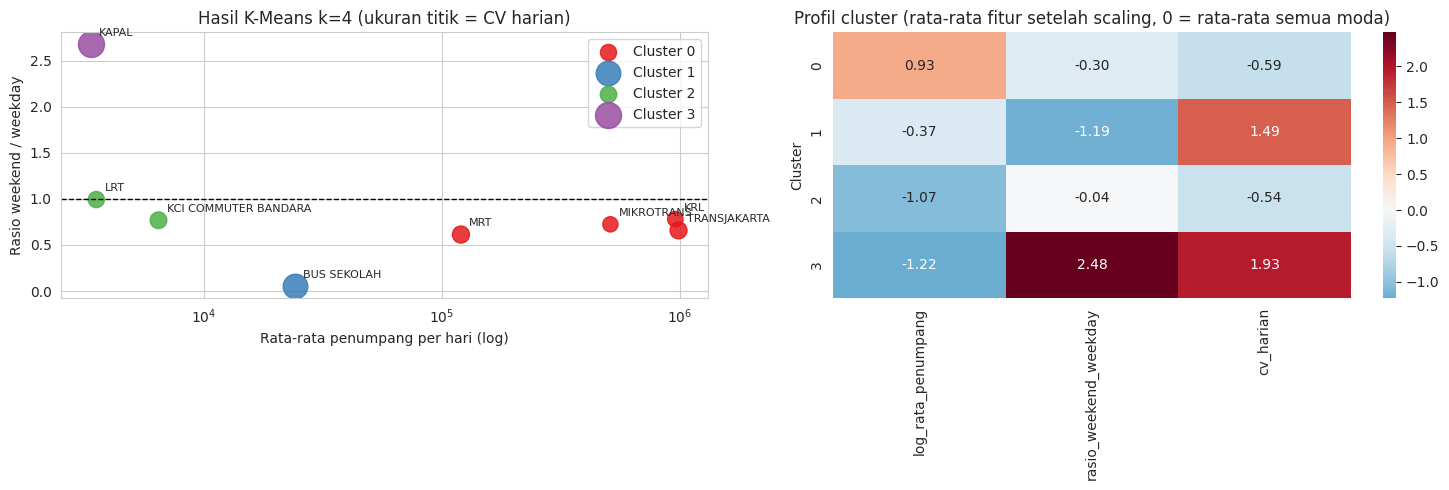

In [116]:
warna = sns.color_palette("Set1", 4)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for c in range(4):
    sub = data_moda[data_moda["cluster_final"] == c]
    ax[0].scatter(sub["rata_penumpang"], sub["rasio_weekend_weekday"], s=60 + 300 * sub["cv_harian"],
                  color=warna[c], label=f"Cluster {c}", alpha=0.85)
for moda, b in data_moda.iterrows():
    ax[0].annotate(moda, (b["rata_penumpang"], b["rasio_weekend_weekday"]),
                   xytext=(6, 6), textcoords="offset points", fontsize=8)
ax[0].axhline(1, ls="--", c="k", lw=1)
ax[0].set_xscale("log")
ax[0].set_xlabel("Rata-rata penumpang per hari (log)")
ax[0].set_ylabel("Rasio weekend / weekday")
ax[0].set_title("Hasil K-Means k=4 (ukuran titik = CV harian)")
ax[0].legend()

pusat = pd.DataFrame(X, columns=nama_fitur).groupby(data_moda["cluster_final"].values).mean()
sns.heatmap(pusat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("Profil cluster (rata-rata fitur setelah scaling, 0 = rata-rata semua moda)")
ax[1].set_ylabel("Cluster")
plt.tight_layout()
plt.show()

| Cluster | Anggota | Ciri utama | Arti |
|---|---|---|---|
| **0** | KRL, MIKROTRANS, MRT, TransJakarta (50%) | Penumpang terbanyak (≈ 644 ribu/hari), turun ± 30% di akhir pekan, stabil | **Komuter massal.** Kapasitas dan frekuensi difokuskan pada hari kerja. |
| **1** | Bus Sekolah (12,5%) | Penumpang menengah (≈ 24 ribu/hari), hampir berhenti di akhir pekan (rasio 0,06), fluktuatif | **Layanan sekolah.** Armada bisa dialihkan saat akhir pekan dan libur sekolah. |
| **2** | KCI Bandara, LRT (25%) | Penumpang sedikit (≈ 3,5-6,5 ribu/hari), merata sepanjang minggu, stabil | **Layanan khusus yang stabil.** Permintaan kecil tetapi tidak terpengaruh hari. |
| **3** | Kapal (12,5%) | Penumpang sedikit (≈ 3,4 ribu/hari), naik di akhir pekan (rasio 2,7), paling fluktuatif | **Rekreasi/wisata.** Armada ditambah saat akhir pekan dan libur panjang. |

**Jawaban pertanyaan analisis ke-3:** moda angkutan umum Jakarta dapat dikelompokkan menjadi 4 pola penggunaan, yaitu komuter massal, layanan sekolah, layanan khusus stabil, dan rekreasi. Pembedanya adalah **waktu** (rasio weekend/weekday) dan **jenis layanan** (skala dan kestabilan).

### C. Pemeriksaan PCA

**Alasan diperiksa:** PCA biasanya dipakai untuk meringkas fitur yang banyak. Project ini hanya punya 3 fitur, jadi PCA tidak benar-benar dibutuhkan. Namun PCA tetap diuji untuk memastikan apakah meringkas menjadi 2 komponen mengubah atau memperbaiki hasil clustering. Scaling dan PCA dijalankan dalam satu `Pipeline`.

In [117]:
from sklearn.decomposition import PCA

pca_penuh = PCA().fit(X)
varians = pd.DataFrame({
    "komponen": [f"PC{i+1}" for i in range(X.shape[1])],
    "explained_variance_ratio": pca_penuh.explained_variance_ratio_,
    "kumulatif": np.cumsum(pca_penuh.explained_variance_ratio_),
})
display(varians)

pipe_pca = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("pca", PCA(n_components=2)),
    ("kmeans", KMeans(n_clusters=4, n_init=10, random_state=42)),
])
label_pca = pipe_pca.fit_predict(data_moda[fitur])
X_pca = pipe_pca[:-1].transform(data_moda[fitur])

tabel_pca = pd.DataFrame([
    {"pendekatan": "Tanpa PCA (fitur asli)", "jumlah fitur/komponen": 3, "explained variance": 1.0,
     "silhouette (ruang fitur asli)": silhouette_score(X, model_final.labels_),
     "silhouette (ruang model)": silhouette_score(X, model_final.labels_),
     "ARI vs tanpa PCA": 1.0},
    {"pendekatan": "Dengan PCA", "jumlah fitur/komponen": 2,
     "explained variance": varians["kumulatif"].iloc[1],
     "silhouette (ruang fitur asli)": silhouette_score(X, label_pca),
     "silhouette (ruang model)": silhouette_score(X_pca, label_pca),
     "ARI vs tanpa PCA": adjusted_rand_score(model_final.labels_, label_pca)},
])
display(tabel_pca)

,komponen,explained_variance_ratio,kumulatif
0,PC1,0.647,0.647
1,PC2,0.188,0.835
2,PC3,0.165,1.000


,pendekatan,jumlah fitur/komponen,explained variance,silhouette (ruang fitur asli),silhouette (ruang model),ARI vs tanpa PCA
0,Tanpa PCA (fitur asli),3,1.000,0.533,0.533,1.000
1,Dengan PCA,2,0.835,0.533,0.512,1.000


| Pendekatan | Fitur/Komponen | Informasi yang tersimpan | Silhouette | Catatan |
|---|---|---|---|---|
| Tanpa PCA | 3 | 100% | 0,533 | Mudah dijelaskan: skala, pola waktu, kestabilan |
| Dengan PCA | 2 | ≈ 83,5% | 0,533 (cluster sama persis, ARI = 1) | Sulit dijelaskan karena komponen adalah campuran fitur |

**Interpretasi:**
- Dua komponen menyimpan ≈ 83,5% informasi, dan hasil pengelompokannya **sama persis** dengan tanpa PCA.
- Silhouette dibandingkan di ruang fitur asli agar adil, karena ruang PCA berukuran berbeda.

**Keputusan: PCA tidak dipakai.** Hasilnya tidak berubah, fiturnya hanya 3 sehingga tidak perlu diringkas, dan PCA justru mempersulit penjelasan hasil.

### D. Ringkasan Eksperimen dan Rencana Pasca-UTS

**Tabel hasil eksperimen:**

| Model | Konfigurasi | Silhouette | Davies-Bouldin | Stabilitas (ARI) | Catatan |
|---|---|---|---|---|---|
| Baseline | K-Means k=3 | 0,435 | 0,619 | 1,00 | Bus Sekolah salah tempat (silhouette 0,07) |
| Kandidat 1 | K-Means k=4 | 0,533 | 0,205 | 1,00 | **Terpilih**: didukung Elbow dan silhouette, serta stabil |
| Kandidat 2 | Agglomerative Ward k=4 | 0,533 | 0,205 | 1,00 | Hasil sama dengan Kandidat 1 |
| Variasi | PCA (2 komponen) + K-Means k=4 | 0,533* | - | - | Hasil sama, tetapi lebih sulit dijelaskan; tidak dipakai |

*dihitung pada ruang fitur asli. Validasi: 5-fold pada tanggal.

**Ringkasan temuan:** moda angkutan umum Jakarta membentuk 4 pola yang stabil: komuter massal, layanan sekolah, layanan khusus stabil, dan rekreasi. Pembeda utamanya adalah rasio penumpang akhir pekan/hari kerja dan skala layanan.

**Keterbatasan:**
1. Hanya 8 moda, sehingga metrik mudah berubah dan dua cluster beranggota satu.
2. Profil dihitung dari rata-rata seluruh periode, jadi perubahan antarbulan (libur Lebaran, libur sekolah) tidak terlihat.
3. Perubahan pencatatan TransJakarta/MIKROTRANS 2026 dan lonjakan KRL Desember 2025 belum diverifikasi ke sumber data.

**Rencana pasca-UTS:**
1. **Hapus satu moda bergantian** (*leave-one-moda-out*) untuk menguji dampak data yang sedikit.
2. **Uji periode:** bandingkan cluster dari data 2024-2025 dengan data 2026 untuk melihat pengaruh perubahan pencatatan TransJakarta/MIKROTRANS.